---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 21

- I Gusti Ngurah Alit Dharma Y (13524072)
- Billy Ontoseno Irawan (13524121)
- Eduard Daniel Ariajaya (13524129)
- Azri Arzaq Pohan (13524139)
- Rasyad Satyatma (13524142)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pada tugas besar ini, diselesaikan persoalan supervised learning berupa klasifikasi biner. Berdasarkan himpunan fitur historis dan detail reservasi tamu, sistem pembelajaran mesin dilatih untuk memetakan setiap data pemesanan ke dalam dua kelas diskret: pemesanan yang dibatalkan (1) dan pemesanan yang tidak dibatalkan (0).

## Aim

Membangun, menguji, dan membandingkan model klasifikasi from scratch dan scikit-learn untuk memprediksi pembatalan pemesanan

## Metric

Kompetisi memakai **macro F1**, yaitu rata-rata F1 kelas "tidak batal" dan kelas "batal":

$$\text{Macro F1} = \tfrac{1}{2}\left(F1_{0} + F1_{1}\right), \qquad F1_c = \frac{2\,TP_c}{2\,TP_c + FP_c + FN_c}.$$

Kedua kelas berbobot sama, sehingga model yang selalu menebak kelas mayoritas (67%) hanya mendapat skor sekitar 0,40.
Karena itu *threshold* keputusan juga disetel, tidak selalu 0,5. *Public leaderboard* hanya memakai sekitar 30% data
test, jadi pemilihan model didasarkan pada *cross-validation*, bukan skor publik.

## Dataset

- `train.csv`: 27.373 pemesanan, 17 fitur, kolom `id`, dan target `is_canceled`.
- `test.csv`: 6.844 pemesanan tanpa target.
- 14 fitur numerik (jumlah tamu, jumlah malam, *lead time*, tanggal kedatangan, harga, riwayat) dan 3 fitur
  kategorikal (`meal_package`, `room_category`, `booking_channel`).
- 8 kolom memiliki nilai kosong (3–11%), dan 39% baris memiliki minimal satu nilai kosong.

## Approach

Pengerjaan mengikuti CRISP-DM:

1. **Data understanding**: distribusi, hubungan fitur dengan target, dan kualitas data.
2. **Split**: `train.csv` dibagi menjadi 80% *development* dan 20% *hold-out* secara berstrata. Semua pilihan
   (preprocessing, hyperparameter, threshold) memakai **5-fold stratified CV pada data development**. Data hold-out
   hanya dipakai di akhir untuk memastikan skor CV tidak terlalu optimistis.
3. **Data preparation**: setiap keputusan diuji dengan CV dan dicatat di blok *Insights*. Semua statistik di-*fit*
   hanya pada fold latih.
4. **Modeling**: lima model *from scratch* ditambah algoritma optimasi di luar materi kuliah (cost-complexity pruning,
   Newton-IRLS, SMO dengan Platt scaling, Tree-Augmented Naive Bayes).
5. **Kaggle Submission**: model terbaik di-*fit* ulang pada seluruh `train.csv` dengan hyperparameter dan threshold yang sudah
   dibekukan, lalu memprediksi `test.csv`.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q -r ../requirements.txt

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import hashlib
import json
import os
import pickle
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'train.csv').exists())
sys.path.insert(0, str(ROOT))

from src import metrics
from src import visualization as viz
from src import config
from src.config import (KNN_THRESHOLD, CART_THRESHOLD, LR_THRESHOLD, KNN_WEIGHTS, KNN_PARAMS,
                        knn_pipeline, knn_model, knn_baseline_pipeline, cart_pipeline, cart_model,
                        lr_pipeline, lr_model, svm_pipeline, svm_model, nb_pipeline, nb_model, tan_model)
from src.data import development_split
from src.evaluation import fit_and_score, report_table, subsample, segment_errors
from src.preprocessing import (TARGET, ID_COLUMN, NUMERIC, CATEGORICAL, RAW_FEATURES, make_pipeline,
                               CategoryEncoder, Imputer, PCA, FeatureBuilder)
from src.validation import StratifiedKFold, cross_validate, stratified_split
from src.models import (KNNClassifier, CARTClassifier, LogisticRegression, SVC, NaiveBayes,
                        TreeAugmentedNaiveBayes)

from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.tree import DecisionTreeClassifier as SkTree
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.svm import SVC as SkSVC
from sklearn.naive_bayes import GaussianNB as SkGaussianNB, CategoricalNB as SkCategoricalNB

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Unknown solver options')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    ROOT       = ROOT
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    FIG_DIR    = OUTPUT_DIR / 'figures'
    MODEL_DIR  = OUTPUT_DIR / 'models'
    SUB_DIR    = OUTPUT_DIR / 'submissions'
    EXP_DIR    = OUTPUT_DIR / 'experiments'
    N_FOLDS    = 5

CFG = Settings()
for folder in [CFG.OUTPUT_DIR, CFG.FIG_DIR, CFG.MODEL_DIR, CFG.SUB_DIR, CFG.EXP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}  Sample submission: {sample_submission.shape}')

Train: (27373, 19)  Test: (6844, 18)  Sample submission: (6844, 2)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
COLUMN_INFO = {
    'id': 'booking ID (unique text)',
    'num_adults': 'number of adult guests',
    'num_children': 'number of child guests',
    'weekend_nights': 'number of weekend nights (Saturday/Sunday)',
    'weekday_nights': 'number of weekday nights',
    'meal_package': 'meal package',
    'needs_parking': 'needs a parking space (0/1)',
    'room_category': 'room category (Type A–G)',
    'days_before_arrival': 'lead time: days between booking and arrival',
    'arrival_year': 'arrival year',
    'arrival_month': 'arrival month',
    'arrival_day': 'arrival day of month',
    'booking_channel': 'booking channel',
    'is_returning_guest': 'guest has stayed before (0/1)',
    'prior_cancellations': 'number of previous cancellations by the guest',
    'prior_completed_bookings': 'number of previous bookings by the guest that were not canceled',
    'nightly_rate_idr': 'price per night (Rupiah)',
    'special_requests': 'number of special requests',
    'is_canceled': 'TARGET: 1 = canceled, 0 = not canceled',
}
describe = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'kind': ['id' if c == 'id' else 'target' if c == TARGET else
             'categorical' if c in CATEGORICAL else 'numeric' for c in train_df.columns],
    'n_unique': train_df.nunique(),
    'example': train_df.iloc[0],
    'meaning': pd.Series(COLUMN_INFO),
})
display(describe)
display(train_df.describe().T)

,dtype,kind,n_unique,example,meaning
id,object,id,27373,57152f82,booking ID (unique text)
num_adults,float64,numeric,5,2.0000,number of adult guests
num_children,float64,numeric,6,NaN,number of child guests
weekend_nights,int64,numeric,8,1,number of weekend nights (Saturday/Sunday)
weekday_nights,int64,numeric,18,2,number of weekday nights
meal_package,object,categorical,4,Breakfast,meal package
needs_parking,float64,numeric,2,0.0000,needs a parking space (0/1)
room_category,object,categorical,7,Type B,room category (Type A–G)
days_before_arrival,float64,numeric,407,88.0000,lead time: days between booking and arrival
arrival_year,int64,numeric,2,2024,arrival year


,count,mean,std,min,25%,50%,75%,max
num_adults,"26,564.0000",1.8452,0.5180,0.0000,2.0000,2.0000,2.0000,4.0000
num_children,"24,338.0000",0.1174,0.4258,0.0000,0.0000,0.0000,0.0000,10.0000
weekend_nights,"27,373.0000",0.8149,0.8751,0.0000,0.0000,1.0000,2.0000,7.0000
weekday_nights,"27,373.0000",2.2065,1.4216,0.0000,1.0000,2.0000,3.0000,17.0000
needs_parking,"26,291.0000",0.0302,0.1711,0.0000,0.0000,0.0000,0.0000,1.0000
days_before_arrival,"26,250.0000",85.3794,85.9696,0.0000,17.0000,58.0000,126.0000,448.0000
arrival_year,"27,373.0000","2,023.8201",0.3841,"2,023.0000","2,024.0000","2,024.0000","2,024.0000","2,024.0000"
arrival_month,"27,373.0000",7.3997,3.0748,1.0000,5.0000,8.0000,10.0000,12.0000
arrival_day,"27,373.0000",15.5375,8.7733,1.0000,8.0000,16.0000,23.0000,31.0000
is_returning_guest,"27,373.0000",0.0252,0.1566,0.0000,0.0000,0.0000,0.0000,1.0000


## Explore Data

This part covers distributions and relationships between attributes.

Class proportion: {0: 0.6723, 1: 0.3277}


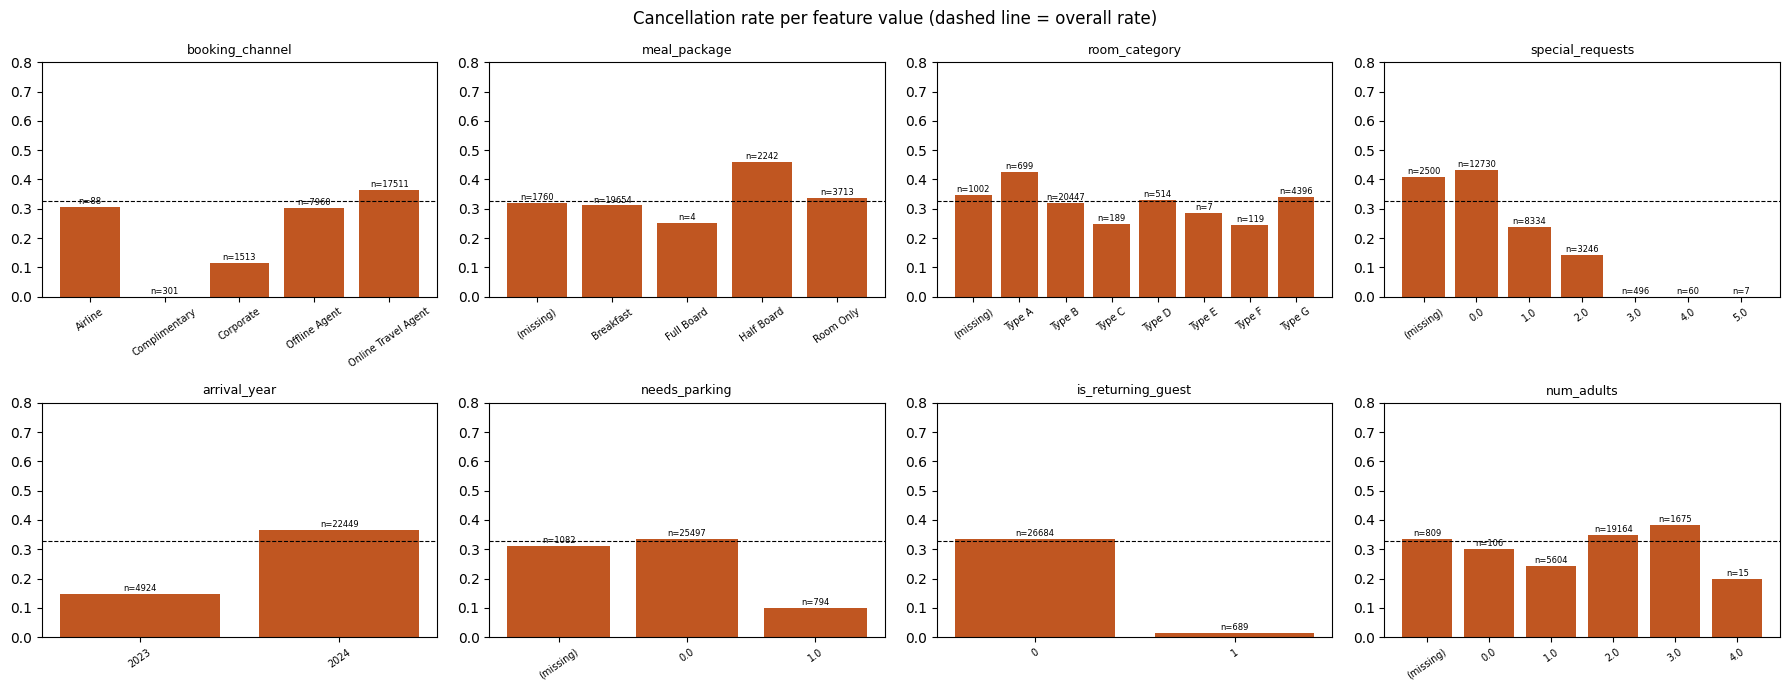

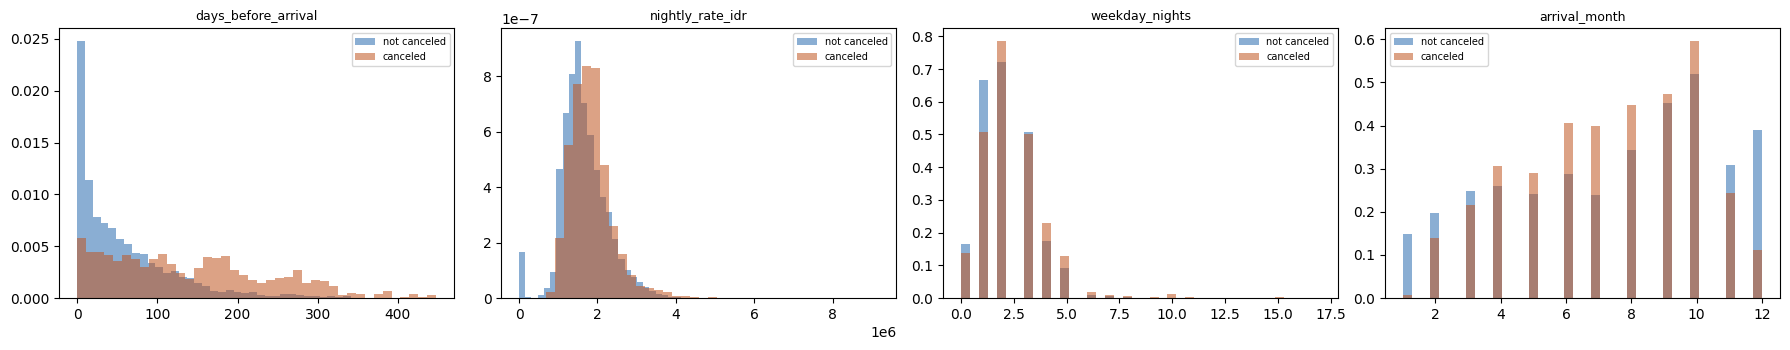

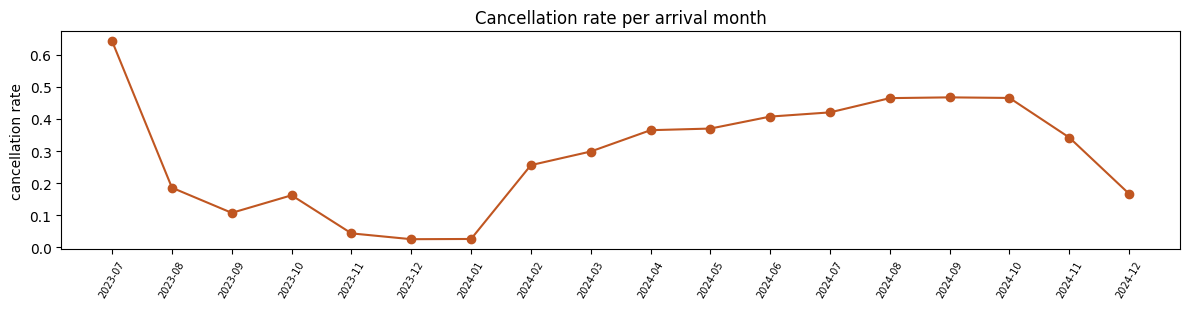

,special_requests,is_returning_guest,prior_completed_bookings,needs_parking,prior_cancellations,arrival_month,arrival_day,num_children,weekend_nights,weekday_nights,num_adults,nightly_rate_idr,arrival_year,days_before_arrival
spearman_vs_target,-0.2614,-0.1072,-0.1024,-0.0855,-0.0575,-0.0370,0.0197,0.0251,0.0528,0.0825,0.0919,0.1477,0.1798,0.4184


In [7]:
y_all = train_df[TARGET]
print('Class proportion:', y_all.value_counts(normalize=True).round(4).to_dict())

discrete = ['booking_channel', 'meal_package', 'room_category', 'special_requests', 'arrival_year',
            'needs_parking', 'is_returning_guest', 'num_adults']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, column in zip(axes.ravel(), discrete):
    stats = train_df.groupby(train_df[column].astype(str).where(train_df[column].notna(), '(missing)'))[TARGET].agg(['mean', 'size'])
    ax.bar(stats.index, stats['mean'], color=viz.COLORS['pos'])
    ax.axhline(y_all.mean(), color='k', ls='--', lw=0.8)
    for i, (rate, n) in enumerate(zip(stats['mean'], stats['size'])):
        ax.text(i, rate + 0.01, f'n={n}', ha='center', fontsize=6)
    ax.set_title(column, fontsize=9)
    ax.tick_params(axis='x', rotation=35, labelsize=7)
    ax.set_ylim(0, 0.8)
fig.suptitle('Cancellation rate per feature value (dashed line = overall rate)')
fig.tight_layout()
fig.savefig(CFG.FIG_DIR / 'eda_cancel_rate_discrete.png', dpi=130)
plt.show()

numeric_plot = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'arrival_month']
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, column in zip(axes, numeric_plot):
    for label, color in [(0, viz.COLORS['neg']), (1, viz.COLORS['pos'])]:
        values = train_df.loc[y_all == label, column].dropna()
        ax.hist(values, bins=40, alpha=0.55, density=True, color=color, label=['not canceled', 'canceled'][label])
    ax.set_title(column, fontsize=9)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(CFG.FIG_DIR / 'eda_numeric_by_class.png', dpi=130)
plt.show()

arrival = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day))
monthly = train_df.groupby(arrival.dt.to_period('M'))[TARGET].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(monthly.index.astype(str), monthly['mean'], marker='o', color=viz.COLORS['pos'])
ax.set_ylabel('cancellation rate'); ax.tick_params(axis='x', rotation=60, labelsize=7)
ax.set_title('Cancellation rate per arrival month')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'eda_monthly_cancel_rate.png', dpi=130); plt.show()

corr = train_df[NUMERIC + [TARGET]].corr(method='spearman')[TARGET].drop(TARGET).sort_values()
display(corr.to_frame('spearman_vs_target').T)

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
features = [c for c in train_df.columns if c not in (ID_COLUMN, TARGET)]
quality = pd.DataFrame({
    'missing_train_%': train_df[features].isna().mean() * 100,
    'missing_test_%': test_df[features].isna().mean() * 100,
    'cancel_rate_if_missing': [train_df.loc[train_df[c].isna(), TARGET].mean() if train_df[c].isna().any() else np.nan for c in features],
    'cancel_rate_if_present': [train_df.loc[train_df[c].notna(), TARGET].mean() for c in features],
}).sort_values('missing_train_%', ascending=False)
display(quality[quality['missing_train_%'] > 0])

n_missing = train_df[features].isna().sum(axis=1)
print('Rows with at least one missing value: train %.1f%%, test %.1f%%' % (
    100 * (n_missing > 0).mean(), 100 * test_df[features].isna().any(axis=1).mean()))
print('Missing values per row:', n_missing.value_counts().sort_index().to_dict())

print('Unique IDs:', train_df[ID_COLUMN].is_unique, '| shared train-test IDs:', len(set(train_df.id) & set(test_df.id)))
print('Duplicated features:', train_df.duplicated(features).sum(),
      '| duplicated features + label:', train_df.duplicated(features + [TARGET]).sum())
arrival_check = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day), errors='coerce')
print('Invalid arrival dates:', arrival_check.isna().sum(), '| range:', arrival_check.min().date(), '-', arrival_check.max().date())
nights = train_df.weekend_nights + train_df.weekday_nights
invalid = {
    'price = 0': int((train_df.nightly_rate_idr == 0).sum()),
    'price = 0 outside Complimentary': int(((train_df.nightly_rate_idr == 0) & (train_df.booking_channel != 'Complimentary')).sum()),
    'adults = 0': int((train_df.num_adults == 0).sum()),
    'total nights = 0': int((nights == 0).sum()),
    'children > 3': int((train_df.num_children > 3).sum()),
}
print('Suspicious values:', invalid)
for column in CATEGORICAL:
    print(f'{column}: train={sorted(train_df[column].dropna().unique())} | only in test={sorted(set(test_df[column].dropna()) - set(train_df[column].dropna()))}')

,missing_train_%,missing_test_%,cancel_rate_if_missing,cancel_rate_if_present
num_children,11.0876,10.9147,0.3282,0.3276
special_requests,9.1331,8.6645,0.4084,0.3195
nightly_rate_idr,7.4453,7.8901,0.3131,0.3288
meal_package,6.4297,6.4582,0.3193,0.3282
days_before_arrival,4.1026,4.2373,0.3117,0.3283
needs_parking,3.9528,3.6090,0.3124,0.3283
room_category,3.6605,3.5359,0.3483,0.3269
num_adults,2.9555,2.6300,0.3350,0.3274


Rows with at least one missing value: train 39.2%, test 39.0%
Missing values per row: {0: 16636, 1: 8478, 2: 1933, 3: 301, 4: 23, 5: 2}
Unique IDs: True | shared train-test IDs: 0
Duplicated features: 66 | duplicated features + label: 64
Invalid arrival dates: 0 | range: 2023-07-01 - 2024-12-30
Suspicious values: {'price = 0': 413, 'price = 0 outside Complimentary': 146, 'adults = 0': 106, 'total nights = 0': 64, 'children > 3': 3}
meal_package: train=['Breakfast', 'Full Board', 'Half Board', 'Room Only'] | only in test=[]
room_category: train=['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G'] | only in test=[]
booking_channel: train=['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent'] | only in test=[]


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
dev_df, hold_df = development_split(train_df, test_size=0.2, random_state=CFG.SEED)
y_dev, y_hold = dev_df[TARGET].to_numpy(), hold_df[TARGET].to_numpy()
print(f'development: {dev_df.shape}, cancellation rate {y_dev.mean():.4f}')
print(f'hold-out   : {hold_df.shape}, cancellation rate {y_hold.mean():.4f}')

def cv(make_pipe, make_model, n_splits=CFG.N_FOLDS, seed=CFG.SEED):
    return cross_validate(make_pipe, make_model, dev_df, y_dev, n_splits=n_splits, random_state=seed)

def cv_table(results):
    return pd.DataFrame({name: {'macroF1@0.5': r.macro_f1_at_half, 'best macroF1': r.best_macro_f1,
                                'threshold': r.best_threshold, 'fold std': np.std(r.fold_macro_f1),
                                'seconds': r.seconds} for name, r in results.items()}).T

def show_cv(results, name):
    table = cv_table(results)
    table.to_csv(CFG.EXP_DIR / f'cv_{name}.csv')
    display(table)

development: (21898, 19), cancellation rate 0.3277
hold-out   : (5475, 19), cancellation rate 0.3277


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

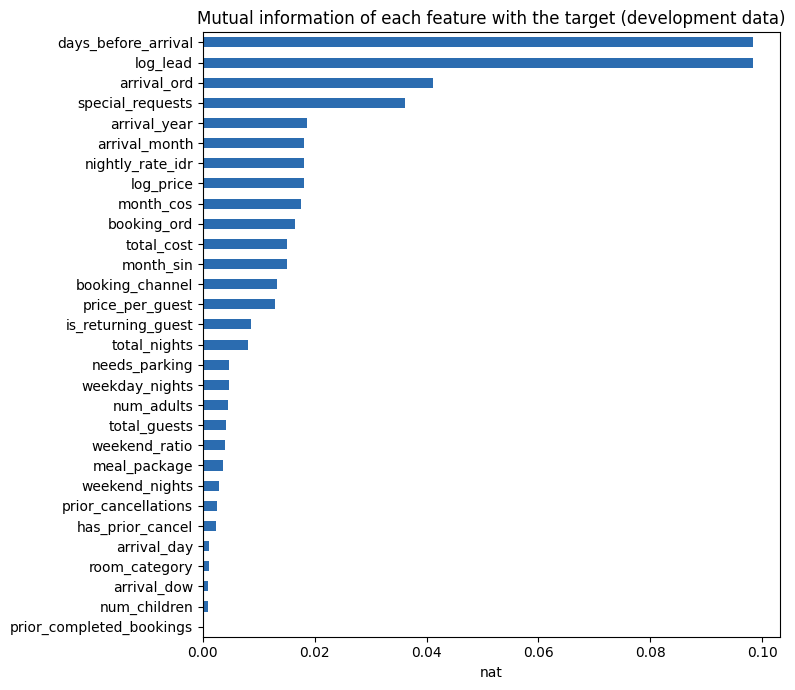

Columns not used as features: ['id']


In [10]:
REF_KNN_COLUMNS = ['days_before_arrival', 'arrival_ord', 'nightly_rate_idr', 'special_requests',
                   'booking_channel=Online Travel Agent', 'booking_channel=Offline Agent',
                   'booking_channel=Corporate', 'total_nights', 'num_adults', 'needs_parking', 'is_returning_guest']
REF_KNN = lambda: KNNClassifier(20, metric='euclidean', weights='distance')

def mutual_information(x, y, n_bins=10):
    x = pd.Series(x)
    if x.dtype != object and x.nunique() > n_bins:
        x = pd.qcut(x, n_bins, duplicates='drop').astype(str)
    x = x.astype(str).where(pd.Series(x).notna(), 'NaN').to_numpy()
    joint = pd.crosstab(x, y).to_numpy() / len(y)
    px, py = joint.sum(1, keepdims=True), joint.sum(0, keepdims=True)
    nz = joint > 0
    return float((joint[nz] * np.log(joint[nz] / (px @ py)[nz])).sum())

selection_view = FeatureBuilder().fit_transform(dev_df[RAW_FEATURES])
mi = pd.Series({c: mutual_information(selection_view[c], y_dev) for c in selection_view.columns}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
mi.iloc[::-1].plot.barh(ax=ax, color=viz.COLORS['neg'])
ax.set_title('Mutual information of each feature with the target (development data)'); ax.set_xlabel('nat')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'feature_mutual_information.png', dpi=130); plt.show()
print('Columns not used as features:', [ID_COLUMN])

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
missing_results = {}
for name, strategy in [('median/mode', 'median'), ('group median', 'group'), ('no imputation (NaN-aware distance)', 'none')]:
    missing_results[f'KNN | {name}'] = cv(lambda s=strategy: make_pipeline('distance', columns=REF_KNN_COLUMNS, impute=s, indicators=()), REF_KNN)
missing_results['KNN | median + special_requests indicator'] = cv(
    lambda: make_pipeline('distance', columns=REF_KNN_COLUMNS + ['special_requests_missing'], indicators=('special_requests',)), REF_KNN)
for name, impute, missing in [('median/mode', 'median', 'learned'), ('learned default direction', 'none', 'learned'),
                              ('fractional (C4.5)', 'none', 'fractional'), ('majority branch', 'none', 'majority')]:
    missing_results[f'CART | {name}'] = cv(lambda i=impute: make_pipeline('tree', impute=i, indicators=()),
                                         lambda m=missing: CARTClassifier(max_depth=10, min_samples_leaf=5, missing=m))
missing_results['NB | skip missing features'] = cv(lambda: make_pipeline('bayes', impute='none', derived=[], indicators=()), lambda: NaiveBayes('discretize', 20))
missing_results['NB | median/mode'] = cv(lambda: make_pipeline('bayes', impute='median', derived=[], indicators=()), lambda: NaiveBayes('discretize', 20))
show_cv(missing_results, 'missing_results')

final_missing_results = {
    'final KNN | median for all columns': cv(lambda: knn_pipeline(knn_impute=()), knn_model),
    'final KNN | KNN regression: lead time': cv(lambda: knn_pipeline(knn_impute=('days_before_arrival',)), knn_model),
    'final KNN | KNN regression: lead time + price (used)': cv(knn_pipeline, knn_model),
    'final KNN | KNN regression: + special_requests': cv(lambda: knn_pipeline(knn_impute=('days_before_arrival', 'nightly_rate_idr', 'special_requests')), knn_model),
}
show_cv(final_missing_results, 'final_missing_results')
lead_missing = hold_df['days_before_arrival'].isna().to_numpy()
for name, impute in [('median', ()), ('KNN regression lead time + price', config.KNN_IMPUTE)]:
    pipe = knn_pipeline(knn_impute=impute)
    scores = knn_model().fit(pipe.fit_transform(dev_df, y_dev), y_dev).predict_proba(pipe.transform(hold_df))[:, 1]
    pred = (scores >= KNN_THRESHOLD).astype(int)
    print(f'{name:34s} hold-out macro F1 = {metrics.macro_f1(y_hold, pred):.4f} | error on rows with missing lead time = '
          f'{np.mean(pred[lead_missing] != y_hold[lead_missing]):.3f} (n={lead_missing.sum()})')

,macroF1@0.5,best macroF1,threshold,fold std,seconds
KNN | median/mode,0.8288,0.8299,0.4800,0.0069,18.3239
KNN | group median,0.8287,0.8293,0.4800,0.0075,19.4011
KNN | no imputation (NaN-aware distance),0.8088,0.8110,0.4700,0.0037,45.8598
KNN | median + special_requests indicator,0.8231,0.8238,0.4800,0.0046,18.7743
CART | median/mode,0.8241,0.8257,0.5700,0.0070,6.3967
CART | learned default direction,0.8237,0.8241,0.5700,0.0058,7.0661
CART | fractional (C4.5),0.8182,0.8207,0.4200,0.0049,8.6529
CART | majority branch,0.8072,0.8099,0.5700,0.0063,6.7350
NB | skip missing features,0.7416,0.7432,0.5100,0.0040,0.4895
NB | median/mode,0.7464,0.7476,0.4700,0.0053,0.5274


,macroF1@0.5,best macroF1,threshold,fold std,seconds
final KNN | median for all columns,0.8508,0.8520,0.4500,0.0033,35.6162
final KNN | KNN regression: lead time,0.8513,0.8525,0.4700,0.0030,46.0548
final KNN | KNN regression: lead time + price (used),0.8524,0.8524,0.4700,0.0023,58.2922
final KNN | KNN regression: + special_requests,0.8443,0.8448,0.5200,0.0040,74.8299


median                             hold-out macro F1 = 0.8568 | error on rows with missing lead time = 0.182 (n=214)


KNN regression lead time + price   hold-out macro F1 = 0.8604 | error on rows with missing lead time = 0.131 (n=214)


### Duplicates

This part covers repeated records.

In [12]:
dup_mask = dev_df.duplicated(RAW_FEATURES, keep=False)
conflict = dev_df[dup_mask].groupby(RAW_FEATURES, dropna=False)[TARGET].nunique()
print('Duplicated feature rows in development:', int(dup_mask.sum()), '| groups with conflicting labels:', int((conflict > 1).sum()))
dup_results = {
    'CART | keep duplicates': cv(lambda: make_pipeline('tree', indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'CART | drop exact duplicates': cv(lambda: make_pipeline('tree', indicators=(), drop_duplicates='keep'), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'CART | drop duplicates + conflicts': cv(lambda: make_pipeline('tree', indicators=(), drop_duplicates='drop'), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
}
show_cv(dup_results, 'dup_results')

Duplicated feature rows in development: 79 | groups with conflicting labels: 0


,macroF1@0.5,best macroF1,threshold,fold std,seconds
CART | keep duplicates,0.8241,0.8257,0.5700,0.0070,7.2377
CART | drop exact duplicates,0.8237,0.8258,0.5700,0.0072,7.0877
CART | drop duplicates + conflicts,0.8237,0.8258,0.5700,0.0072,6.5676


### Outliers

This part covers values far from the rest of the data.

,Q1,Q3,upper fence (Q3+1.5IQR),n outliers,max
column,,,,,
days_before_arrival,17.0000,126.0000,289.5000,739,448.0000
nightly_rate_idr,"1,337,000.0000","2,019,000.0000","3,042,000.0000",924,"9,165,000.0000"
weekday_nights,1.0000,3.0000,6.0000,200,17.0000
weekend_nights,0.0000,2.0000,5.0000,13,7.0000
num_children,0.0000,0.0000,0.0000,1626,10.0000
prior_cancellations,0.0000,0.0000,0.0000,192,11.0000
prior_completed_bookings,0.0000,0.0000,0.0000,476,58.0000


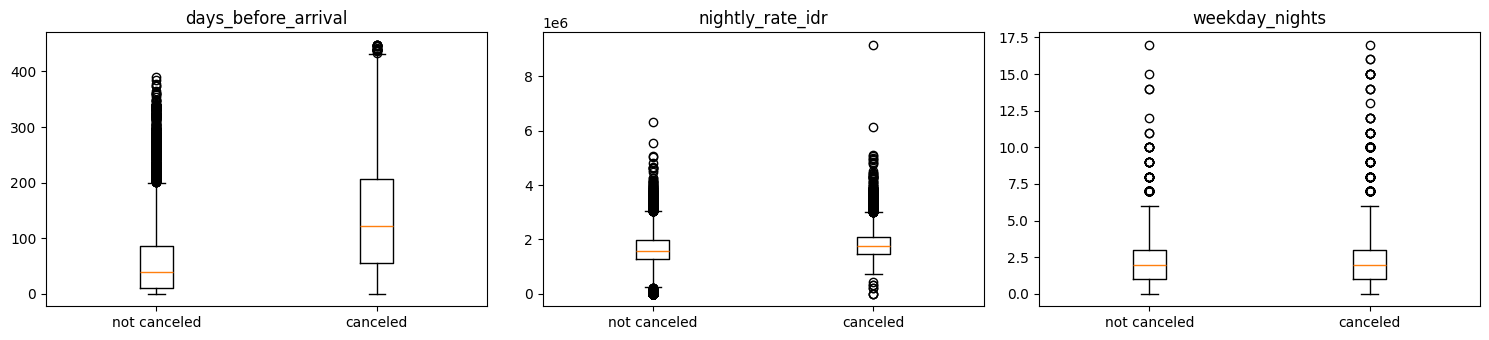

,macroF1@0.5,best macroF1,threshold,fold std,seconds
KNN | standard scaling,0.8288,0.8299,0.4800,0.0069,18.4514
KNN | robust scaling (median/IQR),0.8295,0.8295,0.5000,0.0058,19.8886


In [13]:
outlier_rows = []
for column in ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights', 'num_children',
               'prior_cancellations', 'prior_completed_bookings']:
    values = dev_df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_rows.append({'column': column, 'Q1': q1, 'Q3': q3, 'upper fence (Q3+1.5IQR)': q3 + 1.5 * iqr,
                         'n outliers': int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()),
                         'max': values.max()})
display(pd.DataFrame(outlier_rows).set_index('column'))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, column in zip(axes, ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights']):
    ax.boxplot([dev_df.loc[y_dev == 0, column].dropna(), dev_df.loc[y_dev == 1, column].dropna()], tick_labels=['not canceled', 'canceled'])
    ax.set_title(column)
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'outliers_boxplot.png', dpi=130); plt.show()

outlier_results = {
    'KNN | standard scaling': cv(lambda: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=(), scale='standard'), REF_KNN),
    'KNN | robust scaling (median/IQR)': cv(lambda: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=(), scale='robust'), REF_KNN),
}
show_cv(outlier_results, 'outlier_results')

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
error_results = {}
for name, clean in [('no fix', {'max_children': None}),
                    ('children clipped to 3', {'max_children': 3}),
                    ('+ price 0 outside Complimentary → missing', {'max_children': 3, 'zero_price_to_nan': True}),
                    ('+ adults 0 → missing', {'max_children': 3, 'zero_price_to_nan': True, 'zero_adults_to_nan': True})]:
    error_results[f'KNN | {name}'] = cv(lambda c=clean: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=(), clean=c), REF_KNN)
    error_results[f'CART | {name}'] = cv(lambda c=clean: make_pipeline('tree', indicators=(), clean=c), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5))
show_cv(error_results, 'error_results')
print('Data types:', train_df.dtypes.value_counts().to_dict())
print('Category labels are consistent (no case or spacing variants):', {c: train_df[c].dropna().map(str.strip).nunique() == train_df[c].nunique() for c in CATEGORICAL})

,macroF1@0.5,best macroF1,threshold,fold std,seconds
KNN | no fix,0.8288,0.8299,0.4800,0.0069,18.5201
CART | no fix,0.8241,0.8257,0.5700,0.0070,6.5405
KNN | children clipped to 3,0.8288,0.8299,0.4800,0.0069,17.6781
CART | children clipped to 3,0.8241,0.8257,0.5700,0.0070,6.5136
KNN | + price 0 outside Complimentary → missing,0.8278,0.8288,0.4800,0.0064,20.5503
CART | + price 0 outside Complimentary → missing,0.8243,0.8256,0.4800,0.0059,6.7775
KNN | + adults 0 → missing,0.8281,0.8293,0.4800,0.0064,20.5545
CART | + adults 0 → missing,0.8236,0.8250,0.4800,0.0057,6.4444


Data types: {dtype('int64'): 9, dtype('float64'): 6, dtype('O'): 4}
Category labels are consistent (no case or spacing variants): {'meal_package': True, 'room_category': True, 'booking_channel': True}


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [15]:
constructed = FeatureBuilder().fit_transform(dev_df[RAW_FEATURES])
new_columns = [c for c in constructed.columns if c not in RAW_FEATURES]
display(constructed[new_columns].head())
display(mi.reindex(new_columns).sort_values(ascending=False).to_frame('mutual_information').T)
construct_results = {
    'CART | original features': cv(lambda: make_pipeline('tree', derived=[], indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'CART | + derived features': cv(lambda: make_pipeline('tree', indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'KNN | without arrival_ord (year/month/day)': cv(lambda: make_pipeline('distance', columns=[c for c in REF_KNN_COLUMNS if c != 'arrival_ord'] + ['arrival_year', 'arrival_month'], indicators=()), REF_KNN),
    'KNN | with arrival_ord': cv(lambda: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=()), REF_KNN),
}
show_cv(construct_results, 'construct_results')

,arrival_ord,arrival_dow,booking_ord,total_nights,total_guests,weekend_ratio,total_cost,price_per_guest,log_lead,log_price,month_sin,month_cos,has_prior_cancel
0,458.0000,2.0000,370.0000,3.0000,NaN,0.3333,"3,990,000.0000",NaN,4.4886,14.1007,0.8660,-0.5000,0.0000
1,212.0000,1.0000,92.0000,3.0000,2.0000,0.6667,NaN,NaN,4.7958,NaN,-0.8660,-0.5000,0.0000
2,605.0000,2.0000,396.0000,3.0000,3.0000,0.3333,"6,297,000.0000","699,666.6667",5.3471,14.5570,-0.8660,-0.5000,0.0000
3,590.0000,1.0000,497.0000,3.0000,3.0000,0.6667,"5,079,000.0000","564,333.3333",4.5433,14.3420,-0.8660,-0.5000,0.0000
4,588.0000,6.0000,473.0000,4.0000,2.0000,0.5000,"7,456,000.0000","932,000.0000",4.7536,14.4382,-0.8660,-0.5000,0.0000


,log_lead,arrival_ord,log_price,month_cos,booking_ord,total_cost,month_sin,price_per_guest,total_nights,total_guests,weekend_ratio,has_prior_cancel,arrival_dow
mutual_information,0.0983,0.0411,0.0180,0.0175,0.0165,0.0150,0.0150,0.0129,0.0081,0.0042,0.0039,0.0024,0.0009


,macroF1@0.5,best macroF1,threshold,fold std,seconds
CART | original features,0.8280,0.8285,0.4500,0.0052,3.5304
CART | + derived features,0.8241,0.8257,0.5700,0.0070,6.5231
KNN | without arrival_ord (year/month/day),0.8272,0.8280,0.4800,0.0072,18.2257
KNN | with arrival_ord,0.8288,0.8299,0.4800,0.0069,18.3150


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
scaling_results = {}
for name, method in [('no scaling', None), ('min-max [0,1]', 'minmax'), ('standardization (z-score)', 'standard')]:
    scaling_results[f'KNN | {name}'] = cv(lambda m=method: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=(), scale=m), REF_KNN)
scaling_results['LR | no scaling'] = cv(lambda: make_pipeline('distance', scale=None), lambda: LogisticRegression('l2', C=1.0, solver='newton', max_iter=200))
scaling_results['LR | standardization'] = cv(lambda: make_pipeline('distance'), lambda: LogisticRegression('l2', C=1.0, solver='newton', max_iter=200))
show_cv(scaling_results, 'scaling_results')

,macroF1@0.5,best macroF1,threshold,fold std,seconds
KNN | no scaling,0.6149,0.6219,0.4200,0.0078,26.5719
"KNN | min-max [0,1]",0.8345,0.8360,0.4700,0.0073,17.0398
KNN | standardization (z-score),0.8288,0.8299,0.4800,0.0069,18.4874
LR | no scaling,0.7612,0.7654,0.4500,0.0041,1.9596
LR | standardization,0.7613,0.7655,0.4500,0.0045,1.3299


### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
onehot = CategoryEncoder('onehot', min_frequency=20).fit(dev_df)
ordinal = CategoryEncoder('ordinal', min_frequency=20).fit(dev_df)
for column in CATEGORICAL:
    frequent, rare = onehot.categories_[column]
    print(f'{column}: kept={frequent} | merged into "other"={sorted(rare)}')
display(onehot.transform(dev_df[CATEGORICAL].head()).head())
display(ordinal.transform(dev_df[CATEGORICAL].head()).head())
encoding_results = {
    'CART | native categories (set split)': cv(lambda: make_pipeline('tree', indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'CART | one-hot': cv(lambda: make_pipeline('distance', scale=None, indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
}
show_cv(encoding_results, 'encoding_results')

meal_package: kept=['Breakfast', 'Half Board', 'Room Only'] | merged into "other"=['Full Board']
room_category: kept=['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G'] | merged into "other"=['Type E']
booking_channel: kept=['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent'] | merged into "other"=[]


,meal_package=Breakfast,meal_package=Half Board,meal_package=Room Only,meal_package=other,room_category=Type A,room_category=Type B,room_category=Type C,room_category=Type D,room_category=Type F,room_category=Type G,room_category=other,booking_channel=Airline,booking_channel=Complimentary,booking_channel=Corporate,booking_channel=Offline Agent,booking_channel=Online Travel Agent
0,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
1,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
2,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
3,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
4,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


,meal_package_code,room_category_code,booking_channel_code
0,0.0000,1.0000,3.0000
1,1.0000,3.0000,3.0000
2,0.0000,5.0000,4.0000
3,0.0000,5.0000,4.0000
4,0.0000,1.0000,4.0000


,macroF1@0.5,best macroF1,threshold,fold std,seconds
CART | native categories (set split),0.8241,0.8257,0.5700,0.0070,6.3883
CART | one-hot,0.8243,0.8260,0.5700,0.0059,7.7828


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

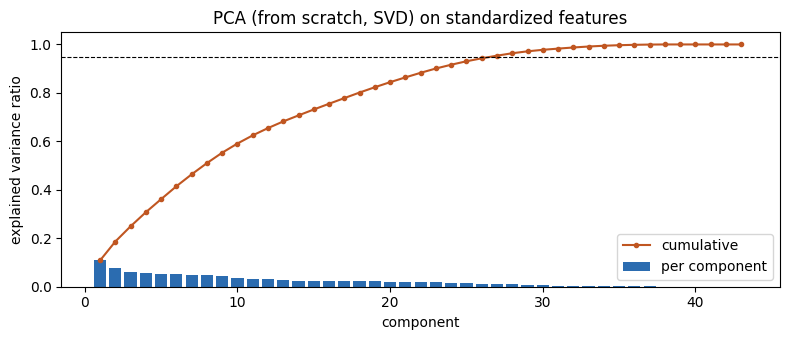

Components for 95% variance: 27 of 43


,macroF1@0.5,best macroF1,threshold,fold std,seconds
KNN | all features,0.8137,0.8138,0.4800,0.0036,16.7255
KNN | PCA 95% variance,0.8143,0.8173,0.4600,0.0040,17.4125
KNN | 11 selected features,0.8288,0.8299,0.4800,0.0069,17.8669


In [18]:
pca_view = make_pipeline('distance', indicators=())
X_pca_input = pd.DataFrame(pca_view.fit_transform(dev_df, y_dev), columns=pca_view.feature_names_)
pca_full = PCA().fit(X_pca_input)
cumulative = np.cumsum(pca_full.explained_variance_ratio_full_)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, len(cumulative) + 1), pca_full.explained_variance_ratio_full_, color=viz.COLORS['neg'], label='per component')
ax.plot(range(1, len(cumulative) + 1), cumulative, color=viz.COLORS['pos'], marker='.', label='cumulative')
ax.axhline(0.95, color='k', ls='--', lw=0.8)
ax.set_xlabel('component'); ax.set_ylabel('explained variance ratio'); ax.legend(); ax.set_title('PCA (from scratch, SVD) on standardized features')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'pca_explained_variance.png', dpi=130); plt.show()
print('Components for 95% variance:', int(np.searchsorted(cumulative, 0.95) + 1), 'of', len(cumulative))
pca_results = {
    'KNN | all features': cv(lambda: make_pipeline('distance', indicators=()), REF_KNN),
    'KNN | PCA 95% variance': cv(lambda: make_pipeline('distance', indicators=(), pca=0.95), REF_KNN),
    'KNN | 11 selected features': cv(lambda: make_pipeline('distance', columns=REF_KNN_COLUMNS, indicators=()), REF_KNN),
}
show_cv(pca_results, 'pca_results')

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
counts = np.bincount(y_dev)
balanced = (len(y_dev) / (2 * counts)).tolist()
print('Rows per class (development):', counts.tolist(), '| balanced weights:', np.round(balanced, 3).tolist())
balance_results = {
    'CART | no handling': cv(lambda: make_pipeline('tree', indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'CART | balanced class_weight': cv(lambda: make_pipeline('tree', indicators=()), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5, class_weight=balanced)),
    'CART | random oversampling': cv(lambda: make_pipeline('tree', indicators=(), oversample=True), lambda: CARTClassifier(max_depth=10, min_samples_leaf=5)),
    'LR | no handling': cv(lambda: make_pipeline('distance'), lambda: LogisticRegression('l2', C=1.0, solver='newton', max_iter=200)),
    'LR | balanced class_weight': cv(lambda: make_pipeline('distance'), lambda: LogisticRegression('l2', C=1.0, solver='newton', max_iter=200, class_weight=balanced)),
    'LR | random oversampling': cv(lambda: make_pipeline('distance', oversample=True), lambda: LogisticRegression('l2', C=1.0, solver='newton', max_iter=200)),
}
show_cv(balance_results, 'balance_results')

Rows per class (development): [14723, 7175] | balanced weights: [0.744, 1.526]


,macroF1@0.5,best macroF1,threshold,fold std,seconds
CART | no handling,0.8241,0.8257,0.5700,0.0070,6.4158
CART | balanced class_weight,0.8172,0.8271,0.7100,0.0071,6.2553
CART | random oversampling,0.8113,0.8243,0.6300,0.0036,7.2606
LR | no handling,0.7613,0.7655,0.4500,0.0045,1.3051
LR | balanced class_weight,0.7542,0.7642,0.6300,0.0047,1.1986
LR | random oversampling,0.7550,0.7639,0.6500,0.0060,1.6954


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
for family, make in [('KNN/SVM (one-hot, z-score, selected features)', knn_pipeline), ('CART (ordinal codes)', cart_pipeline),
                     ('Logistic Regression (one-hot + bins, z-score)', lr_pipeline), ('Naive Bayes (codes, NaN kept)', nb_pipeline)]:
    pipe = make()
    X_fmt, y_fmt = pipe.fit_resample(dev_df, y_dev)
    print(f'{family:48s} X={X_fmt.shape} dtype={X_fmt.dtype} NaN={int(np.isnan(X_fmt).sum())} y={y_fmt.shape}')

KNN/SVM (one-hot, z-score, selected features)    X=(21898, 17) dtype=float64 NaN=0 y=(21898,)


CART (ordinal codes)                             X=(21898, 31) dtype=float64 NaN=0 y=(21898,)


Logistic Regression (one-hot + bins, z-score)    X=(21898, 160) dtype=float64 NaN=0 y=(21898,)
Naive Bayes (codes, NaN kept)                    X=(21898, 17) dtype=float64 NaN=10772 y=(21898,)


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
PIPELINES = {'KNN': knn_pipeline, 'CART': cart_pipeline, 'LogReg': lr_pipeline, 'SVM': svm_pipeline, 'NaiveBayes': nb_pipeline}
fitted_pipelines = {}
for name, make in PIPELINES.items():
    pipe = make().fit(dev_df, y_dev)
    fitted_pipelines[name] = pipe
    print(f'== {name}: {len(pipe.feature_names_)} features')
    for step in pipe.steps:
        print('   ', type(step).__name__, {k: v for k, v in vars(step).items() if not k.endswith('_')})

imputer = next(s for s in fitted_pipelines['CART'].steps if isinstance(s, Imputer))
print('\nExample statistics learned from the training data only (imputation values):',
      {k: imputer.fill_[k] for k in ['num_children', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category']})
print('KNN features:', fitted_pipelines['KNN'].feature_names_)

== KNN: 17 features
    DataCleaner {'zero_price_to_nan': False, 'zero_adults_to_nan': False, 'max_children': 3}
    KNNRegressionImputer {'targets': ('days_before_arrival', 'nightly_rate_idr'), 'n_neighbors': 15, 'cat_weight': 2.0, 'batch_size': 512}
    FeatureBuilder {'features': None}
    Imputer {'strategy': 'median', 'indicators': ('special_requests',), 'group_keys': None}
    CategoryEncoder {'mode': 'onehot', 'min_frequency': 20, 'columns': ['meal_package', 'room_category', 'booking_channel']}
    Scaler {'method': 'standard', 'exclude': ()}
    ColumnSelector {'columns': ['days_before_arrival', 'arrival_ord', 'special_requests', 'log_price', 'booking_ord', 'nightly_rate_idr', 'booking_channel=Online Travel Agent', 'booking_channel=Offline Agent', 'booking_channel=Corporate', 'total_nights', 'needs_parking', 'is_returning_guest', 'arrival_day', 'num_adults', 'weekend_nights', 'room_category=Type C', 'log_lead'], 'weights': {'days_before_arrival': 3.0, 'arrival_ord': 2.0, 'speci

== LogReg: 160 features
    DataCleaner {'zero_price_to_nan': False, 'zero_adults_to_nan': False, 'max_children': 3}
    FeatureBuilder {'features': None}
    Imputer {'strategy': 'median', 'indicators': ('special_requests',), 'group_keys': None}
    QuantileBinner {'columns': ('days_before_arrival', 'nightly_rate_idr', 'arrival_ord', 'booking_ord', 'total_nights', 'price_per_guest', 'arrival_day'), 'n_bins': 20}
    CategoryEncoder {'mode': 'onehot', 'min_frequency': 20, 'columns': ['meal_package', 'room_category', 'booking_channel']}
    Scaler {'method': 'standard', 'exclude': ()}


== SVM: 17 features
    DataCleaner {'zero_price_to_nan': False, 'zero_adults_to_nan': False, 'max_children': 3}
    KNNRegressionImputer {'targets': ('days_before_arrival', 'nightly_rate_idr'), 'n_neighbors': 15, 'cat_weight': 2.0, 'batch_size': 512}
    FeatureBuilder {'features': None}
    Imputer {'strategy': 'median', 'indicators': ('special_requests',), 'group_keys': None}
    CategoryEncoder {'mode': 'onehot', 'min_frequency': 20, 'columns': ['meal_package', 'room_category', 'booking_channel']}
    Scaler {'method': 'standard', 'exclude': ()}
    ColumnSelector {'columns': ['days_before_arrival', 'arrival_ord', 'special_requests', 'log_price', 'booking_ord', 'nightly_rate_idr', 'booking_channel=Online Travel Agent', 'booking_channel=Offline Agent', 'booking_channel=Corporate', 'total_nights', 'needs_parking', 'is_returning_guest', 'arrival_day', 'num_adults', 'weekend_nights', 'room_category=Type C', 'log_lead'], 'weights': {'days_before_arrival': 3.0, 'arrival_ord': 2.0, 'speci

Pipeline (`src/preprocessing.py`) menjalankan `DataCleaner → (KNNRegressionImputer) → FeatureBuilder → Imputer →
(QuantileBinner) → CategoryEncoder → (Scaler) → (ColumnSelector) → (PCA)`. `fit` hanya dipanggil pada data latih,
sedangkan `transform` memakai statistik yang tersimpan tanpa membuang atau menambah baris. Operasi tingkat baris yang
hanya sah untuk data latih (membuang duplikat, oversampling) ada di `fit_resample`.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors


This part covers the nearest neighbor classifier and its validation.

,macro_f1,accuracy,f1_0,f1_1,precision_1,recall_1,threshold,fit_s,predict_s
model,,,,,,,,,
"KNN baseline (k=5, Euclidean, majority vote, all features)",0.8059,0.8323,0.8775,0.7344,0.7635,0.7074,0.5000,0.0812,5.6272
Weighted KNN (final),0.8604,0.8782,0.9102,0.8106,0.8263,0.7954,0.4800,5.4506,14.6661


hold-out #0 (label 0): distances=[1.339, 1.852, 1.898, 2.704, 2.732] neighbor labels=[0, 0, 0, 0, 0]
hold-out #1 (label 0): distances=[1.564, 1.676, 2.044, 2.184, 2.358] neighbor labels=[0, 0, 0, 0, 0]
hold-out #2 (label 1): distances=[0.006, 0.028, 0.032, 0.038, 0.06] neighbor labels=[1, 1, 1, 1, 1]


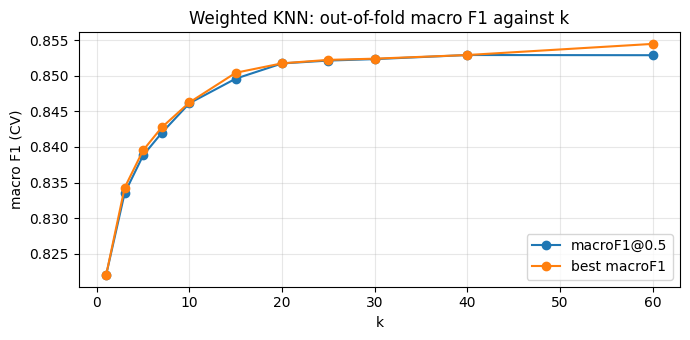

In [22]:
results = {}

results['KNN baseline'] = fit_and_score('KNN baseline (k=5, Euclidean, majority vote, all features)', knn_baseline_pipeline(),
                                        KNNClassifier(**config.KNN_BASELINE_PARAMS), dev_df, y_dev, hold_df, 0.5)
results['KNN'] = fit_and_score('Weighted KNN (final)', knn_pipeline(), knn_model(), dev_df, y_dev, hold_df, KNN_THRESHOLD)
knn_hold = report_table([results['KNN baseline'], results['KNN']], y_hold); knn_hold.to_csv(CFG.EXP_DIR / 'knn_holdout.csv'); display(knn_hold)

knn_res = results['KNN']
X_hold_knn = knn_res.pipeline.transform(hold_df)
dist, idx = knn_res.model.kneighbors(X_hold_knn[:3], n_neighbors=5)
for i in range(3):
    print(f'hold-out #{i} (label {y_hold[i]}): distances={np.round(dist[i], 3).tolist()} neighbor labels={y_dev[idx[i]].tolist()}')

ks = [1, 3, 5, 7, 10, 15, 20, 25, 30, 40, 60]
oof_k = {k: np.zeros(len(y_dev)) for k in ks}
for tr, va in StratifiedKFold(CFG.N_FOLDS, True, CFG.SEED).split(y_dev):
    pipe = knn_pipeline()
    Xtr = pipe.fit_transform(dev_df.iloc[tr], y_dev[tr])
    model = knn_model(n_neighbors=max(ks)).fit(Xtr, y_dev[tr])
    for k, proba in model.predict_proba_multi_k(pipe.transform(dev_df.iloc[va]), ks).items():
        oof_k[k][va] = proba[:, 1]
k_curve = pd.DataFrame({k: {'macroF1@0.5': metrics.macro_f1(y_dev, (s >= 0.5).astype(int)),
                            'best macroF1': metrics.best_threshold(y_dev, s)[1]} for k, s in oof_k.items()}).T
k_curve.to_csv(CFG.EXP_DIR / 'knn_k_curve.csv')
fig, ax = plt.subplots(figsize=(7, 3.5))
k_curve.plot(ax=ax, marker='o'); ax.set_xlabel('k'); ax.set_ylabel('macro F1 (CV)'); ax.grid(alpha=0.3)
ax.set_title('Weighted KNN: out-of-fold macro F1 against k')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'knn_k_curve.png', dpi=130); plt.show()

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

Depth 12, 166 leaves


,leaves,depth,hold-out macro_f1 @0.5,accuracy
variant,,,,
no pruning,2468,33,0.8154,0.8365
"pre-pruning (depth 10, min leaf 5)",315,10,0.8377,0.8590
"Reduced Error Pruning (2/3 grow, 1/3 validation)",379,27,0.8333,0.8574
"cost-complexity (depth 12, ccp 2e-4), final",166,12,0.8399,0.8623


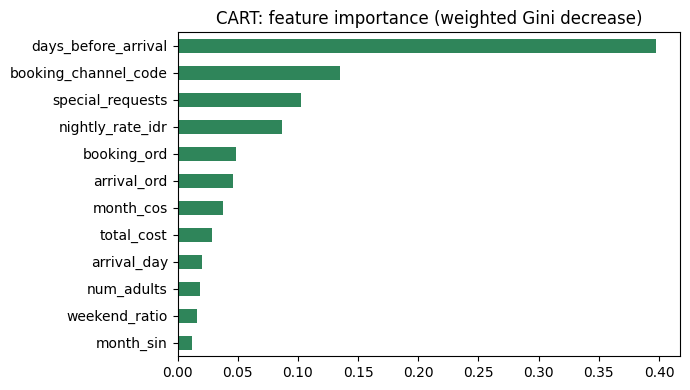

In [23]:
results['CART'] = fit_and_score('CART (Gini, depth 12, ccp 2e-4)', cart_pipeline(), cart_model(), dev_df, y_dev, hold_df, CART_THRESHOLD)
cart = results['CART'].model
print(f'Depth {cart.get_depth()}, {cart.get_n_leaves()} leaves')

X_dev_tree = results['CART'].pipeline.transform(dev_df)
X_hold_tree = results['CART'].pipeline.transform(hold_df)
cat_idx = results['CART'].pipeline.categorical_indices_
variants = {
    'no pruning': CARTClassifier(categorical_features=cat_idx).fit(X_dev_tree, y_dev),
    'pre-pruning (depth 10, min leaf 5)': CARTClassifier(max_depth=10, min_samples_leaf=5, categorical_features=cat_idx).fit(X_dev_tree, y_dev),
}
grow, prune = next(StratifiedKFold(3, True, CFG.SEED).split(y_dev))
rep_tree = CARTClassifier(categorical_features=cat_idx).fit(X_dev_tree[grow], y_dev[grow])
variants['Reduced Error Pruning (2/3 grow, 1/3 validation)'] = rep_tree.prune_reduced_error(X_dev_tree[prune], y_dev[prune])
variants['cost-complexity (depth 12, ccp 2e-4), final'] = cart
rows = []
for name, model in variants.items():
    pred = model.predict(X_hold_tree)
    rows.append({'variant': name, 'leaves': model.get_n_leaves(), 'depth': model.get_depth(),
                 'hold-out macro_f1 @0.5': metrics.macro_f1(y_hold, pred), 'accuracy': metrics.accuracy(y_hold, pred)})
pruning_table = pd.DataFrame(rows).set_index('variant'); pruning_table.to_csv(CFG.EXP_DIR / 'cart_pruning_variants.csv'); display(pruning_table)

importance = pd.Series(cart.feature_importances_, index=results['CART'].pipeline.feature_names_).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7, 4)); importance.iloc[::-1].plot.barh(ax=ax, color=viz.COLORS['accent'])
ax.set_title('CART: feature importance (weighted Gini decrease)'); fig.tight_layout()
fig.savefig(CFG.FIG_DIR / 'cart_feature_importance.png', dpi=130); plt.show()

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

,macro_f1,accuracy,zero coefficients,coefficients,fit_s
model,,,,,
LogReg no regularization,0.7890,0.8152,0,160,0.6755
LogReg L2 (C=3),0.7858,0.8128,0,160,0.4756
LogReg L1 (C=0.05),0.7839,0.8117,36,160,1.1824
"LogReg Elastic Net (C=0.05, ρ=0.5)",0.7829,0.8104,24,160,1.2176


,epochs/iterations,seconds,final objective,hold-out macro_f1
solver,,,,
SGA (lecture),15,5.9934,-0.3986,0.7838
mini-batch GA,60,2.8356,-0.4050,0.7796
batch GA,300,3.4969,-0.3986,0.7847
Adam,60,2.9616,-0.4033,0.7800
Newton-IRLS,12,0.2908,-0.3967,0.7858


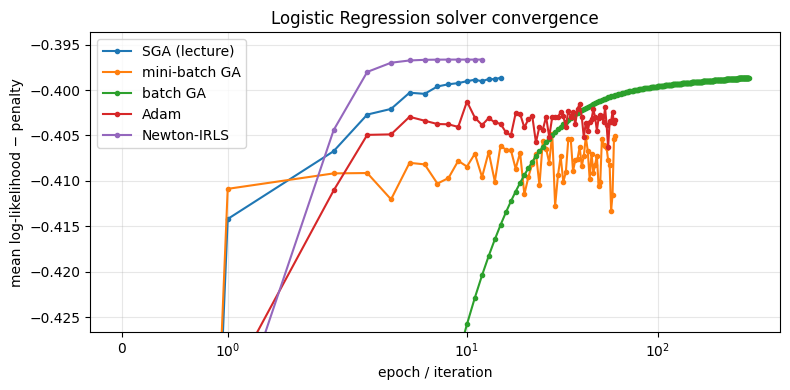

In [24]:
lr_rows, lr_models = [], {}
for name, params in [('no regularization', {'penalty': 'none'}), ('L2 (C=3)', {'penalty': 'l2', 'C': 3.0}),
                     ('L1 (C=0.05)', {'penalty': 'l1', 'C': 0.05}), ('Elastic Net (C=0.05, ρ=0.5)', {'penalty': 'elasticnet', 'C': 0.05, 'l1_ratio': 0.5})]:
    res = fit_and_score(f'LogReg {name}', lr_pipeline(), LogisticRegression(solver='newton', max_iter=200, **params), dev_df, y_dev, hold_df, LR_THRESHOLD)
    lr_models[name] = res
    lr_rows.append({**report_table([res], y_hold).iloc[0].to_dict(), 'zero coefficients': int(np.sum(res.model.coef_ == 0)),
                    'coefficients': len(res.model.coef_), 'model': res.name})
lr_table = pd.DataFrame(lr_rows).set_index('model')[['macro_f1', 'accuracy', 'zero coefficients', 'coefficients', 'fit_s']]
lr_table.to_csv(CFG.EXP_DIR / 'logreg_regularization.csv'); display(lr_table)
results['LogReg'] = lr_models['L2 (C=3)']

X_dev_lr = results['LogReg'].pipeline.transform(dev_df)
X_hold_lr = results['LogReg'].pipeline.transform(hold_df)
solver_rows, solver_curves = [], {}
for name, params in [('SGA (lecture)', dict(solver='sga', learning_rate=0.01, decay=1e-4, max_iter=15)),
                     ('mini-batch GA', dict(solver='minibatch', learning_rate=0.5, batch_size=256, max_iter=60)),
                     ('batch GA', dict(solver='batch', learning_rate=1.0, max_iter=300)),
                     ('Adam', dict(solver='adam', learning_rate=0.01, batch_size=256, max_iter=60)),
                     ('Newton-IRLS', dict(solver='newton', max_iter=50))]:
    t0 = time.perf_counter()
    model = LogisticRegression(penalty='l2', C=3.0, tol=1e-9, **params).fit(X_dev_lr, y_dev)
    seconds = time.perf_counter() - t0
    solver_curves[name] = model.history_['objective']
    solver_rows.append({'solver': name, 'epochs/iterations': model.n_iter_, 'seconds': seconds,
                        'final objective': model.history_['objective'][-1],
                        'hold-out macro_f1': metrics.macro_f1(y_hold, model.predict(X_hold_lr, threshold=LR_THRESHOLD))})
solver_table = pd.DataFrame(solver_rows).set_index('solver'); solver_table.to_csv(CFG.EXP_DIR / 'logreg_solvers.csv'); display(solver_table)
fig, ax = plt.subplots(figsize=(8, 4))
for name, curve in solver_curves.items():
    ax.plot(range(len(curve)), curve, marker='.', label=name)
ax.set_xscale('symlog'); ax.set_xlabel('epoch / iteration'); ax.set_ylabel('mean log-likelihood − penalty')
best_obj = solver_rows[-1]['final objective']
ax.set_ylim(best_obj - 0.03, best_obj + 0.003)
ax.legend(); ax.grid(alpha=0.3); ax.set_title('Logistic Regression solver convergence')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'logreg_solver_convergence.png', dpi=130); plt.show()

## Support Vector Machine


This part covers the linear, polynomial, and Gaussian kernels.

In [25]:
take_svm = subsample(config.SVM_SUBSAMPLE, random_state=CFG.SEED)
svm_rows = []
for kernel in ['linear', 'poly', 'rbf']:
    res = fit_and_score(f'SVM {kernel}', svm_pipeline(), svm_model(kernel), dev_df, y_dev, hold_df, config.SVM_THRESHOLDS[kernel], model_X=take_svm)
    results[f'SVM {kernel}'] = res
    m = res.model
    svm_rows.append({'kernel': kernel, **{k: v for k, v in m.get_params().items() if k in ('C', 'gamma', 'degree', 'coef0')},
                     'effective gamma': m._gamma, 'SMO iterations': m.n_iter_, 'support vectors': len(m.support_),
                     'bounded SV (α=C)': int(np.sum(np.isclose(m.alpha_, m.C))), 'Σξ': m.slack_total,
                     'hold-out macro_f1': metrics.macro_f1(y_hold, res.predictions), 'fit_s': res.fit_seconds})
svm_table = pd.DataFrame(svm_rows).set_index('kernel'); svm_table.to_csv(CFG.EXP_DIR / 'svm_kernels.csv'); display(svm_table)

,C,degree,gamma,coef0,effective gamma,SMO iterations,support vectors,bounded SV (α=C),Σξ,hold-out macro_f1,fit_s
kernel,,,,,,,,,,,
linear,1.0000,3,scale,0.0000,0.0283,100,3371,2772,"2,842.4967",0.7661,16.5599
poly,3.0000,3,scale,1.0000,0.0283,100,3097,2180,"2,181.8078",0.8018,46.5603
rbf,10.0000,3,scale,0.0000,0.0283,100,2725,1966,"1,868.8262",0.8186,30.9418


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [26]:
results['NB Gaussian'] = fit_and_score('Gaussian Naive Bayes', nb_pipeline(), nb_model(continuous='gaussian'), dev_df, y_dev, hold_df, 0.5)
results['NaiveBayes'] = fit_and_score('Discrete Naive Bayes (20 bins)', nb_pipeline(), nb_model(), dev_df, y_dev, hold_df, 0.5)
results['TAN'] = fit_and_score('Tree-Augmented Naive Bayes (20 bins)', nb_pipeline(), tan_model(), dev_df, y_dev, hold_df, 0.5)
nb_hold = report_table([results['NB Gaussian'], results['NaiveBayes'], results['TAN']], y_hold); nb_hold.to_csv(CFG.EXP_DIR / 'nb_holdout.csv'); display(nb_hold)
nb_cv = {
    'Gaussian NB': cv(nb_pipeline, lambda: nb_model(continuous='gaussian')),
    'discrete NB': cv(nb_pipeline, nb_model),
    'TAN': cv(nb_pipeline, tan_model),
}
show_cv(nb_cv, 'nb_cv')

,macro_f1,accuracy,f1_0,f1_1,precision_1,recall_1,threshold,fit_s,predict_s
model,,,,,,,,,
Gaussian Naive Bayes,0.6905,0.7647,0.8421,0.5390,0.7530,0.4197,0.5000,0.0528,0.0214
Discrete Naive Bayes (20 bins),0.7458,0.7836,0.8438,0.6478,0.6938,0.6076,0.5000,0.0538,0.0176
Tree-Augmented Naive Bayes (20 bins),0.7814,0.8141,0.8659,0.6968,0.7481,0.6522,0.5000,0.1499,0.0179


,macroF1@0.5,best macroF1,threshold,fold std,seconds
Gaussian NB,0.6848,0.6941,0.4200,0.0070,0.4417
discrete NB,0.7416,0.7432,0.5100,0.0040,0.4951
TAN,0.7747,0.7771,0.4400,0.0085,0.8707


## Model Evaluation


This part compares the validation results of all models.

,macro_f1,accuracy,f1_0,f1_1,precision_1,recall_1,threshold,fit_s,predict_s
model,,,,,,,,,
Weighted KNN (final),0.8604,0.8782,0.9102,0.8106,0.8263,0.7954,0.4800,5.4506,14.6661
"KNN baseline (k=5, Euclidean, majority vote, all features)",0.8059,0.8323,0.8775,0.7344,0.7635,0.7074,0.5000,0.0812,5.6272
"CART (Gini, depth 12, ccp 2e-4)",0.8399,0.8623,0.8998,0.7799,0.8186,0.7447,0.5200,2.4849,0.0311
SVM rbf,0.8186,0.8438,0.8863,0.7509,0.7865,0.7185,0.4300,30.9418,1.7501
SVM poly,0.8018,0.8289,0.8751,0.7285,0.7586,0.7007,0.4100,46.5603,2.0655
SVM linear,0.7661,0.7965,0.8505,0.6817,0.6993,0.6650,0.4300,16.5599,1.3648
LogReg L2 (C=3),0.7858,0.8128,0.8618,0.7097,0.7214,0.6984,0.4400,0.4756,0.0832
Tree-Augmented Naive Bayes (20 bins),0.7814,0.8141,0.8659,0.6968,0.7481,0.6522,0.5000,0.1499,0.0179
Discrete Naive Bayes (20 bins),0.7458,0.7836,0.8438,0.6478,0.6938,0.6076,0.5000,0.0538,0.0176


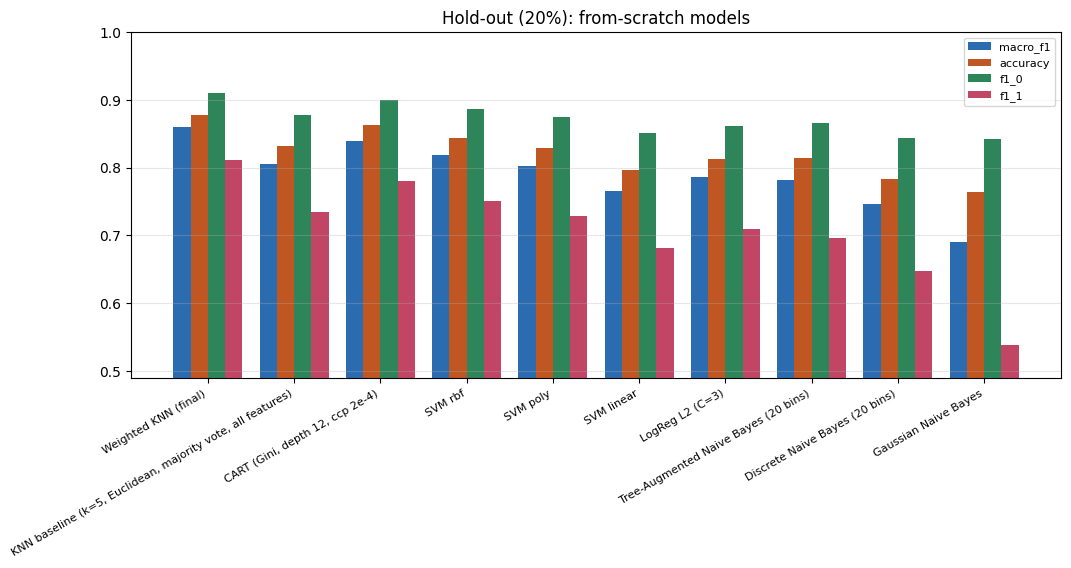

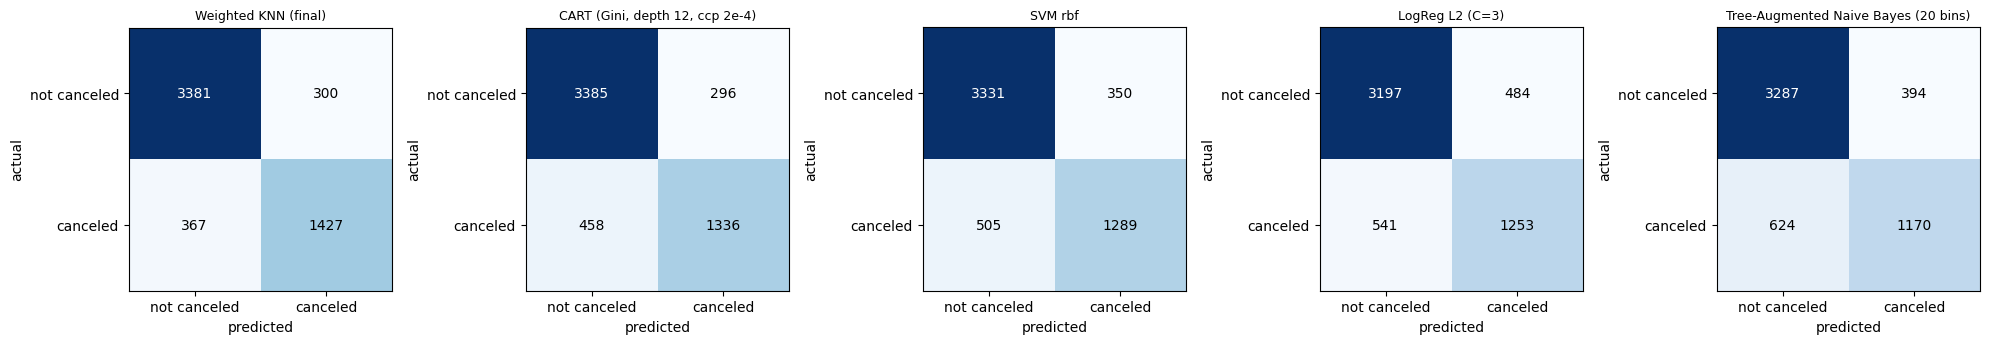

In [27]:
order = ['KNN', 'KNN baseline', 'CART', 'SVM rbf', 'SVM poly', 'SVM linear', 'LogReg', 'TAN', 'NaiveBayes', 'NB Gaussian']
holdout_table = report_table([results[k] for k in order], y_hold)
display(holdout_table)
holdout_table.to_csv(CFG.EXP_DIR / 'holdout_results.csv')
viz.plot_metric_comparison(holdout_table, ['macro_f1', 'accuracy', 'f1_0', 'f1_1'], path=CFG.FIG_DIR / 'holdout_model_comparison.png',
                           title='Hold-out (20%): from-scratch models')
plt.show()
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, key in zip(axes, ['KNN', 'CART', 'SVM rbf', 'LogReg', 'TAN']):
    viz.plot_confusion(metrics.confusion_matrix(y_hold, results[key].predictions, labels=[0, 1]), ax, results[key].name)
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'holdout_confusion_matrices.png', dpi=130); plt.show()

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [28]:
repeat_rows = []
for name, make_pipe, make_model in [('KNN baseline (lecture)', knn_baseline_pipeline, lambda: KNNClassifier(**config.KNN_BASELINE_PARAMS)),
                                    ('Weighted KNN (final)', knn_pipeline, knn_model),
                                    ('final CART', cart_pipeline, cart_model)]:
    scores = [cv(make_pipe, make_model, seed=s) for s in (0, 1, 2)]
    repeat_rows.append({'model': name, 'best macroF1 (mean)': np.mean([r.best_macro_f1 for r in scores]),
                        'std across seeds': np.std([r.best_macro_f1 for r in scores]),
                        'threshold (mean)': np.mean([r.best_threshold for r in scores])})
repeat_table = pd.DataFrame(repeat_rows).set_index('model'); repeat_table.to_csv(CFG.EXP_DIR / 'repeated_cv.csv'); display(repeat_table)

search_logs = [CFG.EXP_DIR / 'knn_ascent_manhattan.json', CFG.EXP_DIR / 'knn_ascent_euclidean.json',
               CFG.EXP_DIR / 'knn_ascent_manhattan_round2.json']
for path in search_logs:
    log = json.loads(path.read_text())
    print(f"{path.name}: metric={log['args']['metric']} OOF macroF1={log['macro_f1']:.4f} k={log['k']} threshold={log['threshold']}")
weights_table = pd.Series(KNN_WEIGHTS).sort_values(ascending=False).to_frame('final weight')
display(weights_table.T)

powers, ks_grid = [0.5, 1.0, 1.5, 2.0, 3.0], [15, 20, 25, 30, 40]
oof_pk = {(p, k): np.zeros(len(y_dev)) for p in powers for k in ks_grid}
for tr, va in StratifiedKFold(CFG.N_FOLDS, True, CFG.SEED).split(y_dev):
    pipe = knn_pipeline()
    model = knn_model(n_neighbors=max(ks_grid)).fit(pipe.fit_transform(dev_df.iloc[tr], y_dev[tr]), y_dev[tr])
    dist, idx = model.kneighbors(pipe.transform(dev_df.iloc[va]))
    for p in powers:
        model.distance_power = p
        for k in ks_grid:
            oof_pk[(p, k)][va] = model._vote(dist[:, :k], idx[:, :k])[:, 1]
power_table = pd.DataFrame({k: {p: metrics.best_threshold(y_dev, oof_pk[(p, k)])[1] for p in powers} for k in ks_grid})
power_table.index.name, power_table.columns.name = 'p (vote weight 1/d^p)', 'k'
power_table.to_csv(CFG.EXP_DIR / 'knn_power_k_grid.csv')
display(power_table.style.format('{:.4f}').highlight_max(axis=None))

,best macroF1 (mean),std across seeds,threshold (mean)
model,,,
KNN baseline (lecture),0.8001,0.0004,0.5100
Weighted KNN (final),0.8546,0.0013,0.4633
final CART,0.8306,0.0004,0.4833


knn_ascent_manhattan.json: metric=manhattan OOF macroF1=0.8491 k=20 threshold=0.48
knn_ascent_euclidean.json: metric=euclidean OOF macroF1=0.8453 k=25 threshold=0.49
knn_ascent_manhattan_round2.json: metric=manhattan OOF macroF1=0.8544 k=40 threshold=0.48


,days_before_arrival,arrival_ord,special_requests,log_price,booking_ord,nightly_rate_idr,booking_channel=Online Travel Agent,booking_channel=Offline Agent,booking_channel=Corporate,total_nights,needs_parking,is_returning_guest,arrival_day,num_adults,weekend_nights,room_category=Type C,log_lead
final weight,3.0000,2.0000,2.0000,2.0000,2.0000,1.5000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5000,0.5000,0.5000,0.5000


k,15,20,25,30,40
p (vote weight 1/d^p),,,,,
0.500000,0.8433,0.8426,0.8397,0.8389,0.8359
1.000000,0.8499,0.8503,0.8487,0.8495,0.8475
1.500000,0.8508,0.8522,0.8519,0.8523,0.8533
2.000000,0.8504,0.8518,0.8522,0.8524,0.8529
3.000000,0.8463,0.8474,0.8482,0.8492,0.8502


**Tuning KNN** 

Bobot fitur dipelajari dengan *coordinate ascent* pada macro F1 *out-of-fold*: untuk setiap fitur dari 44 kandidat, bobotnya dicoba diganti dengan setiap nilai pada kisi
{0; 0,5; 1; 2; 3}, dan perubahan diterima jika skor CV naik minimal 0,0005. Ini adalah seleksi fitur *wrapper*
(Kohavi & John 1997) sekaligus pembobotan fitur (Wettschereck dkk. 1997).

- Manhattan: CV naik dari 0,8408 ke 0,8491 setelah satu putaran. Putaran kedua tidak menemukan perbaikan sehingga
  dihentikan. Fitur yang ditambahkan oleh pencarian adalah `arrival_day`, `arrival_month`, `weekend_nights`,
  `log_price`, dan `room_category=Type C`.
- Euclidean: CV naik ke 0,8453, tetapi turun di hold-out (tanda *overfitting* ke fold), sehingga ditolak.
- Putaran lanjutan: pencarian diulang mulai dari bobot Manhattan di atas, tetapi dengan fold seed 7 dan kisi yang
  ditambah nilai 1,5 , supaya bobot tidak hanya cocok dengan fold seed 42. CV seed 7 naik
  dari 0,8502 ke 0,8544. Perubahannya: `arrival_month` dibuang, `arrival_ord` 3 → 2, `nightly_rate_idr` 2 → 1,5,
  serta fitur baru `booking_ord` (2) dan `log_lead` (0,5). Pada CV 5-fold di lima seed lain (101, 202, 303, 404,
  505), bobot ini lebih baik daripada bobot putaran pertama di setiap seed (rata-rata +0,002 pada k = 30). Skor
  publik Kaggle juga naik, sehingga bobot inilah yang dipakai di model final.
- Bobot suara 1/d^p: tabel di atas membandingkan p dan k pada CV. p = 1,5 dan p = 2 hampir setara dan lebih baik
  daripada 1/d (Dudani 1976), sedangkan p = 3 kembali turun. p = 2 (Shepard 1968) dipertahankan.
- Model final memakai bobot hasil putaran lanjutan tersebut, suara 1/d², imputasi KNN-regresi untuk lead time dan harga,
  k = 30, dan threshold 0,48.
- CV berulang dengan seed lain (tabel paling atas) memberi simpangan baku yang sangat kecil, sehingga peringkat model
  tidak bergantung pada satu pembagian fold. Karena bobot dipilih dengan fold seed 42 (dan seed 7), skor CV seed 42
  sedikit optimistis, dan skor hold-out adalah estimasi yang sesungguhnya

### Bonus: algoritma optimasi model (di luar materi kuliah)

| Model | Algoritma | Cara mengoptimasi | Referensi |
| --- | --- | --- | --- |
| DTL | Minimal cost-complexity pruning | memangkas *weakest link* g(t) = (R(t) − R(T_t)) / (\|T_t\| − 1) dan memilih α lewat CV, menyeimbangkan galat dan kompleksitas pohon | Breiman dkk. 1984 |
| Logistic Regression | Newton-IRLS (+ proximal Newton untuk L1/Elastic Net), Adam sebagai pembanding | Newton memakai Hessian sehingga konvergen kuadratik; langkah proksimal membuat koefisien L1 tepat nol | Hastie dkk. 2009 §4.4.1; Lee, Sun & Saunders 2014; Kingma & Ba 2015 |
| SVM | SMO + Platt scaling | memecah QP dual menjadi sub-masalah dua variabel yang punya solusi analitik, dengan α kedua dipilih dari \|E_i − E_j\| terbesar; nilai keputusan lalu dikalibrasi menjadi probabilitas dengan sigmoid | Platt 1998; Platt 1999 |
| Naive Bayes | Tree-Augmented Naive Bayes | menambah sisi antarfitur dari *maximum spanning tree* atas *conditional mutual information* (Chow-Liu) | Friedman, Geiger & Goldszmidt 1997; Chow & Liu 1968 |

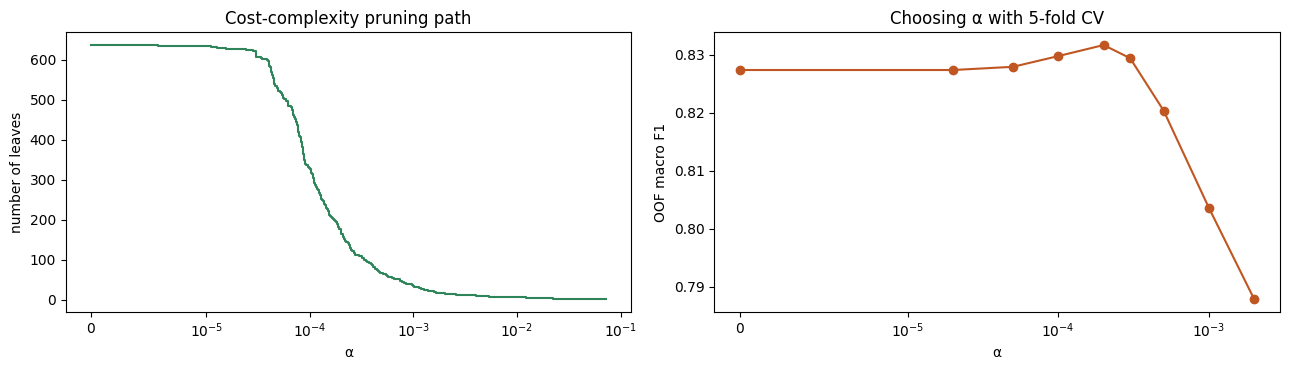

Best α (CV): 0.0002 | macro F1: 0.8317


In [29]:
path_tree = CARTClassifier(max_depth=12, categorical_features=cat_idx).fit(X_dev_tree, y_dev)
ccp_path = path_tree.cost_complexity_pruning_path()
alphas = [0.0, 2e-5, 5e-5, 1e-4, 2e-4, 3e-4, 5e-4, 1e-3, 2e-3]
oof_alpha = {a: np.zeros(len(y_dev)) for a in alphas}
for tr, va in StratifiedKFold(CFG.N_FOLDS, True, CFG.SEED).split(y_dev):
    pipe = cart_pipeline()
    Xtr = pipe.fit_transform(dev_df.iloc[tr], y_dev[tr])
    full = CARTClassifier(max_depth=12, categorical_features=pipe.categorical_indices_).fit(Xtr, y_dev[tr])
    Xva = pipe.transform(dev_df.iloc[va])
    for a in alphas:
        oof_alpha[a][va] = full.pruned_copy(a).predict_proba(Xva)[:, 1]
alpha_curve = pd.Series({a: metrics.best_threshold(y_dev, s)[1] for a, s in oof_alpha.items()})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.plot(ccp_path['ccp_alphas'], ccp_path['n_leaves'], drawstyle='steps-post', color=viz.COLORS['accent'])
ax1.set_xscale('symlog', linthresh=1e-5); ax1.set_xlabel('α'); ax1.set_ylabel('number of leaves'); ax1.set_title('Cost-complexity pruning path')
ax2.plot(alpha_curve.index, alpha_curve.values, marker='o', color=viz.COLORS['pos'])
ax2.set_xscale('symlog', linthresh=1e-5); ax2.set_xlabel('α'); ax2.set_ylabel('OOF macro F1'); ax2.set_title('Choosing α with 5-fold CV')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'cart_ccp_alpha.png', dpi=130); plt.show()
alpha_curve.to_frame('macro_f1_oof').to_csv(CFG.EXP_DIR / 'cart_alpha_cv.csv')
print('Best α (CV):', alpha_curve.idxmax(), '| macro F1:', round(alpha_curve.max(), 4))

### Bonus: gambar percabangan pohon (parameter `top_n`)

`viz.plot_tree(model, feature_names, top_n=N)` menggambar N percabangan teratas (per tingkat dari akar, atau
`order='samples'` untuk cabang dengan sampel terbanyak). Cabang lain diringkas menjadi kotak "… subtree".

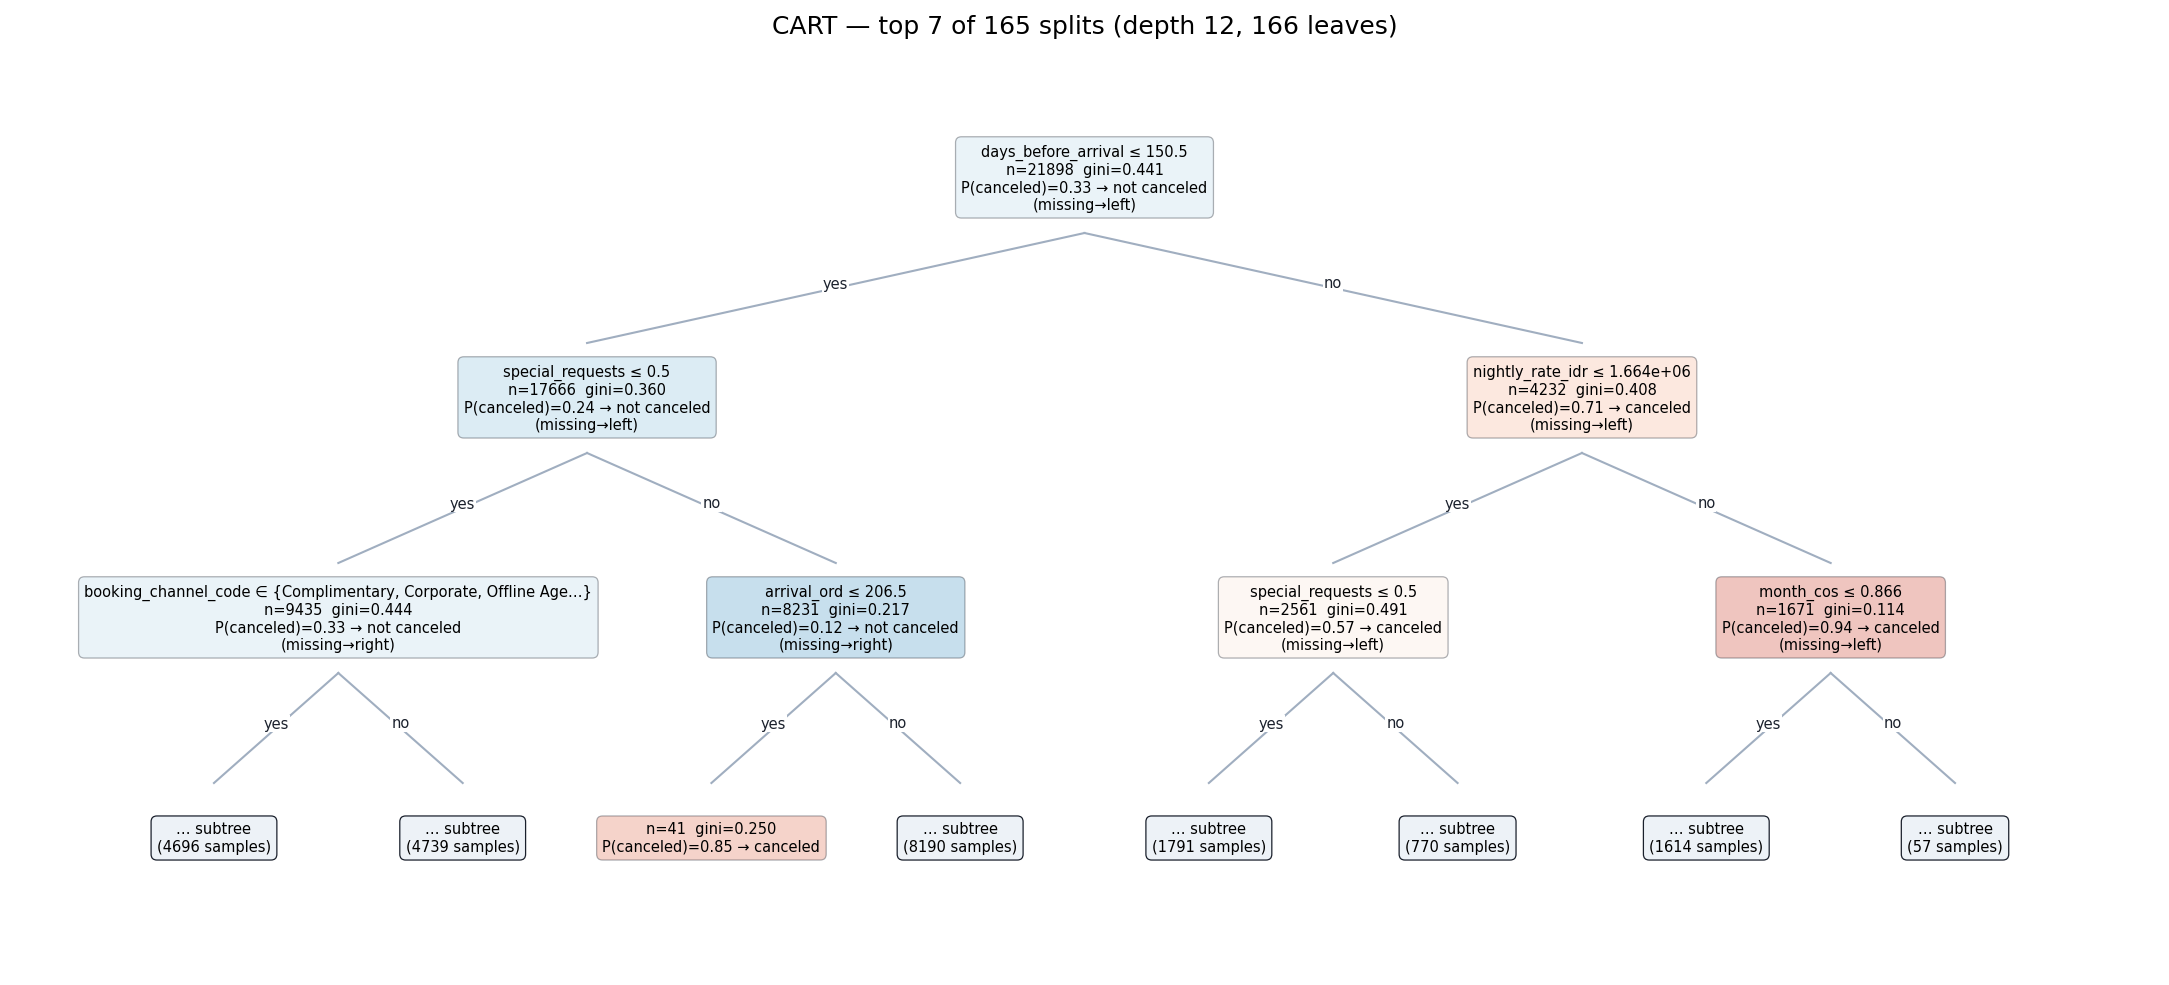

Other figure: output/figures/cart_tree_top15.png


In [30]:
cart_encoder = next(s for s in results['CART'].pipeline.steps if isinstance(s, CategoryEncoder))
tree_feature_names = results['CART'].pipeline.feature_names_
category_names = {tree_feature_names.index(f'{c}_code'): cart_encoder.categories_[c][0] + (['other'] if cart_encoder.categories_[c][1] else [])
                  for c in CATEGORICAL}
for top_n in (7, 15):
    viz.plot_tree(cart, tree_feature_names, top_n=top_n, category_names=category_names,
                  path=CFG.FIG_DIR / f'cart_tree_top{top_n}.png')
    plt.close('all')
display(Image(filename=str(CFG.FIG_DIR / 'cart_tree_top7.png')))
print('Other figure:', (CFG.FIG_DIR / 'cart_tree_top15.png').relative_to(CFG.ROOT))

### Bonus: video kontur log-loss dan lintasan (θ₀, θ₁)

Model logistik dua parameter p = σ(θ₀ + θ₁·x) dengan x = `days_before_arrival` yang distandardisasi. Kontur adalah
log-loss rata-rata pada kisi (θ₀, θ₁), dan setiap lintasan menunjukkan parameter di setiap langkah untuk empat solver.

Video: output/figures/logreg_trajectory.mp4


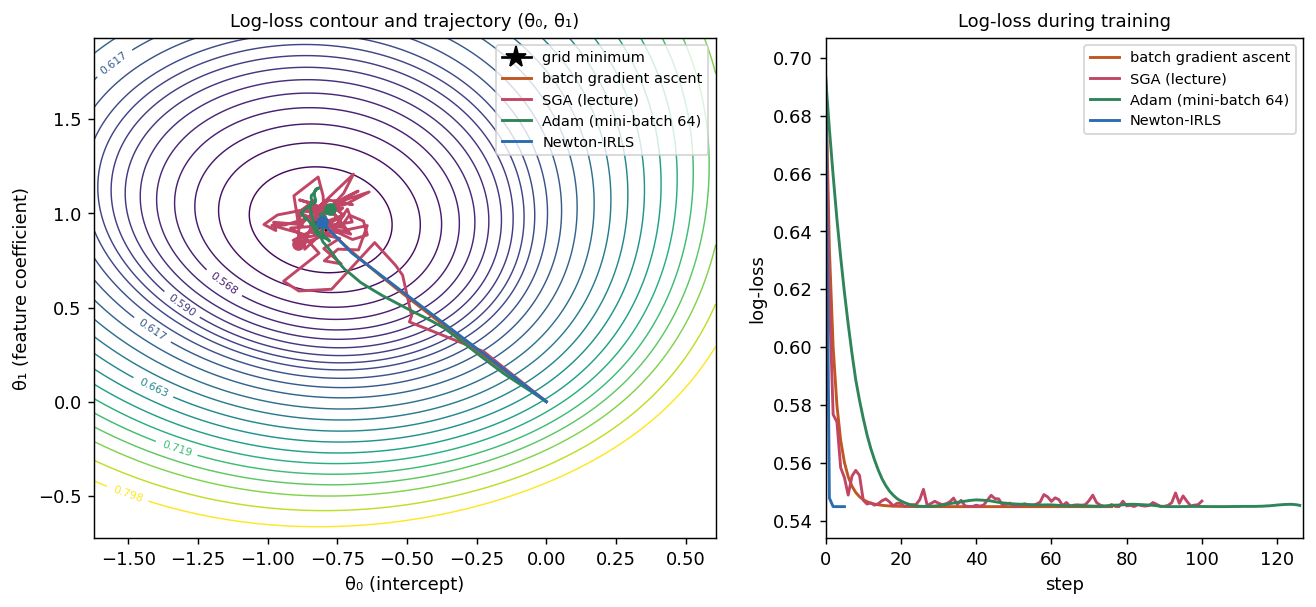

In [31]:
lead = dev_df['days_before_arrival'].fillna(dev_df['days_before_arrival'].median()).to_numpy()
x_video = ((lead - lead.mean()) / lead.std())[:4000][:, None]
y_video = y_dev[:4000]
trajectories = {}
for name, params, every in [('batch gradient ascent', dict(solver='batch', learning_rate=1.0, max_iter=80), 1),
                            ('SGA (lecture)', dict(solver='sga', learning_rate=0.02, max_iter=2), 80),
                            ('Adam (mini-batch 64)', dict(solver='adam', learning_rate=0.05, batch_size=64, max_iter=2), 1),
                            ('Newton-IRLS', dict(solver='newton', max_iter=10), 1)]:
    model = LogisticRegression(penalty='none', record_history=True, tol=1e-12, **params).fit(x_video, y_video)
    trajectories[name] = np.array(model.history_['params'])[::every]
video_path = viz.animate_logreg_contour(x_video[:, 0], y_video, trajectories, CFG.FIG_DIR / 'logreg_trajectory.mp4', fps=15)
print('Video:', video_path.relative_to(CFG.ROOT))
display(Image(filename=str(video_path.with_suffix('.png'))))

### Bonus: bidang pemisah, margin, dan support vector SVM

Setiap kernel dilatih pada proyeksi PCA 2D (fitur KNN terbobot) dari 1.500 baris development. Garis tebal adalah
f(x) = 0 (bidang pemisah), garis putus-putus adalah margin f(x) = ±1, dan titik yang dilingkari adalah support vector.

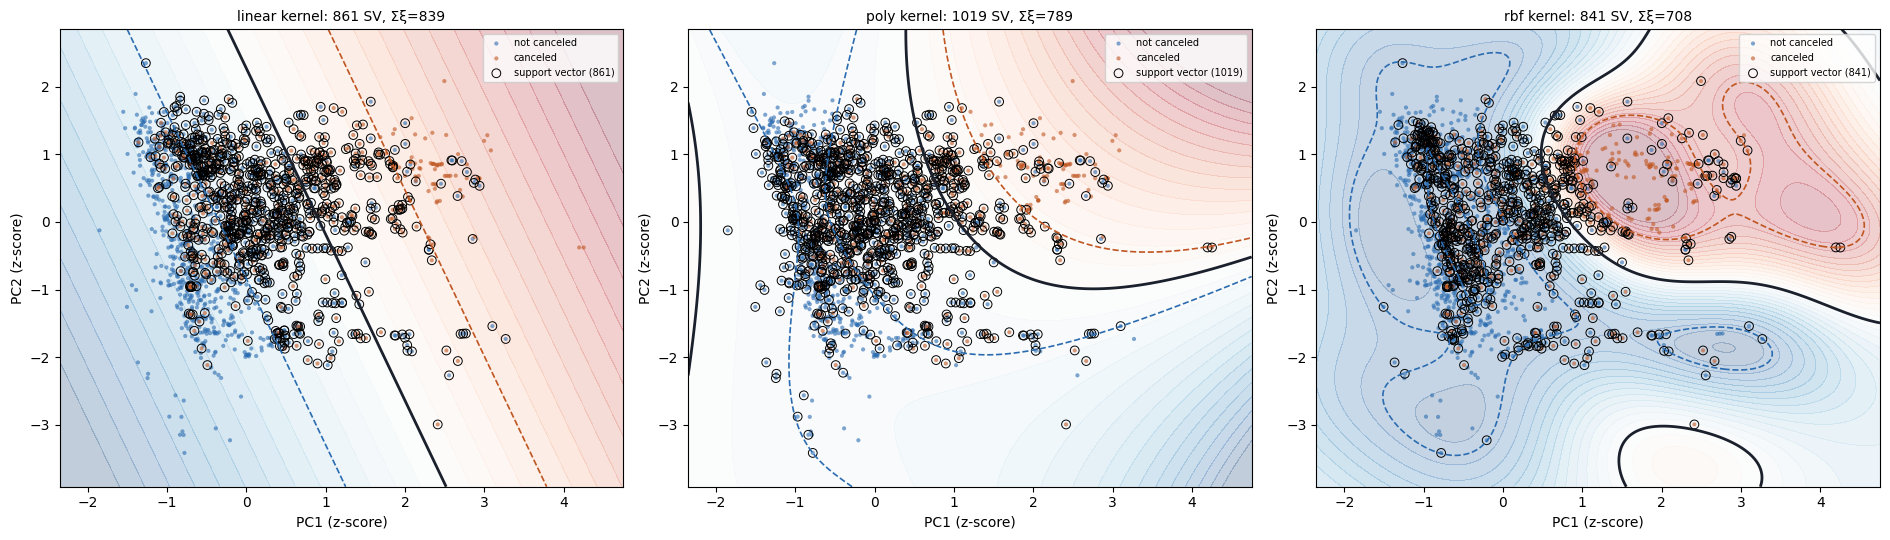

In [32]:
svm_view = svm_pipeline()
X_svm_all = svm_view.fit_transform(dev_df, y_dev)
_, idx_2d = stratified_split(y_dev, test_size=1500 / len(y_dev), random_state=CFG.SEED)
pca2 = PCA(2).fit(pd.DataFrame(X_svm_all[idx_2d]))
X2_raw = pca2.transform(pd.DataFrame(X_svm_all[idx_2d])).to_numpy()
X2 = (X2_raw - X2_raw.mean(axis=0)) / X2_raw.std(axis=0)
y2 = y_dev[idx_2d]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (kernel, params) in zip(axes, [('linear', dict(kernel='linear', C=1.0)),
                                       ('poly', dict(kernel='poly', C=1.0, degree=3, gamma='scale', coef0=1.0)),
                                       ('rbf', dict(kernel='rbf', C=1.0, gamma='scale'))]):
    model2d = SVC(**params).fit(X2, y2)
    if model2d.n_iter_ >= model2d.max_passes:
        print(f'warning: SMO for the {kernel} kernel hit max_passes')
    viz.plot_svm_boundary(model2d, X2, y2, ax=ax, feature_names=('PC1 (z-score)', 'PC2 (z-score)'),
                          title=f'{kernel} kernel: {len(model2d.support_)} SV, Σξ={model2d.slack_total:.0f}')
    single, sax = plt.subplots(figsize=(6.5, 5.5))
    viz.plot_svm_boundary(model2d, X2, y2, ax=sax, feature_names=('PC1 (z-score)', 'PC2 (z-score)'), title=f'SVM {kernel} kernel (2D PCA)')
    single.savefig(CFG.FIG_DIR / f'svm_boundary_{kernel}.png', dpi=130, bbox_inches='tight'); plt.close(single)
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'svm_boundaries.png', dpi=130); plt.show()

### Bonus: graf Bayesian Network

Kiri: Naive Bayes (kelas → setiap fitur, tebal panah = *mutual information* fitur dengan kelas). Kanan: struktur TAN
yang dipelajari (sisi ungu = orang tua fitur dari *maximum spanning tree conditional mutual information*, simpul hijau
= akar).

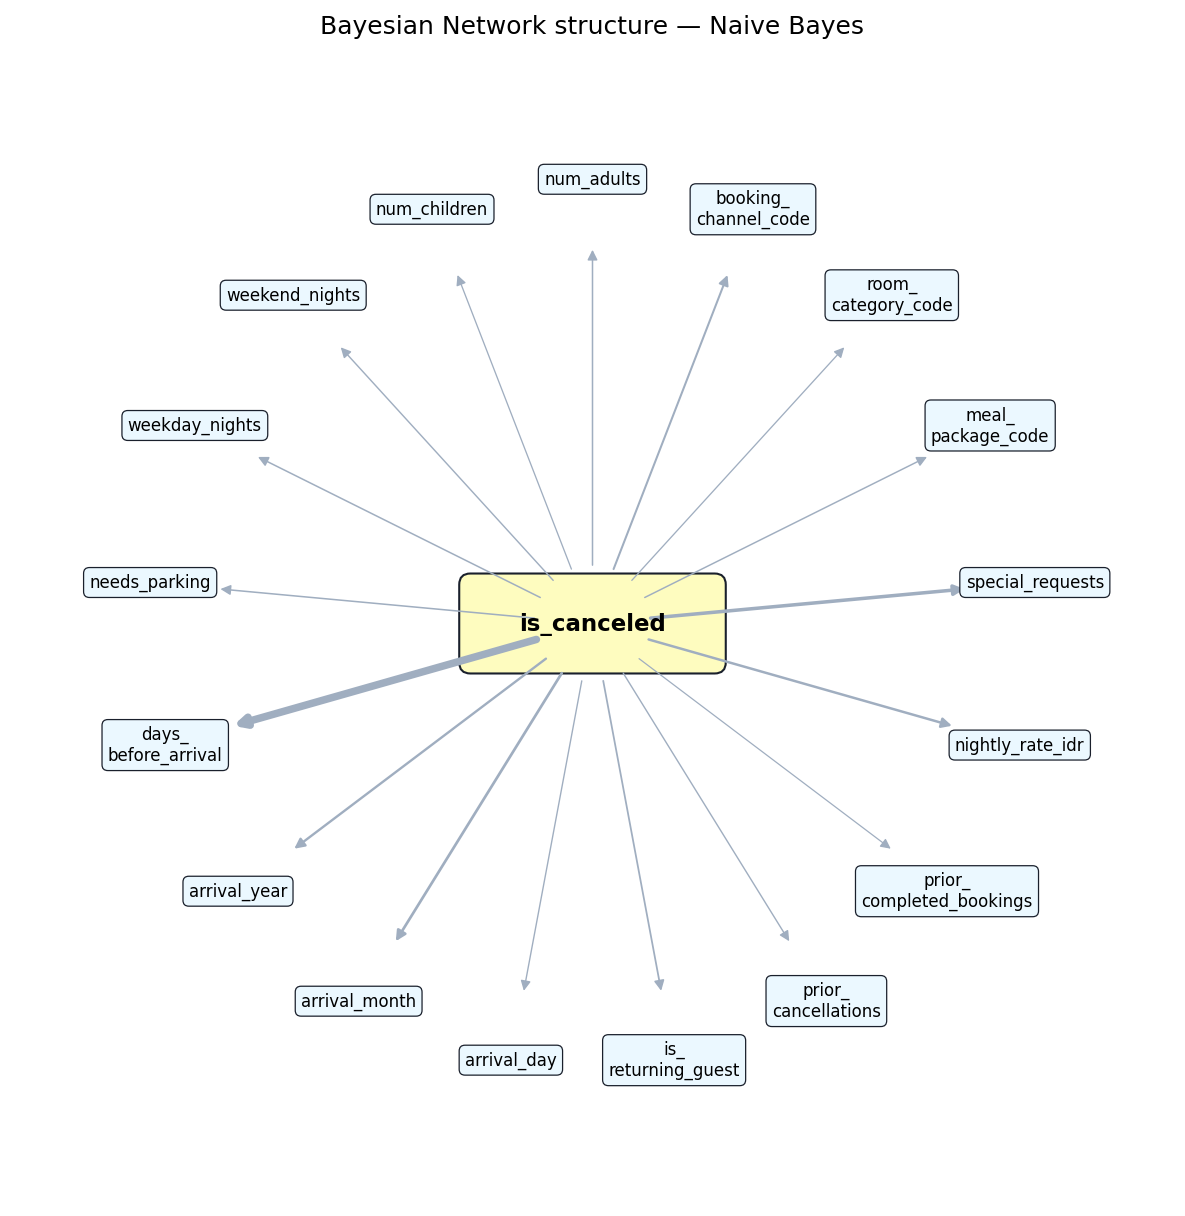

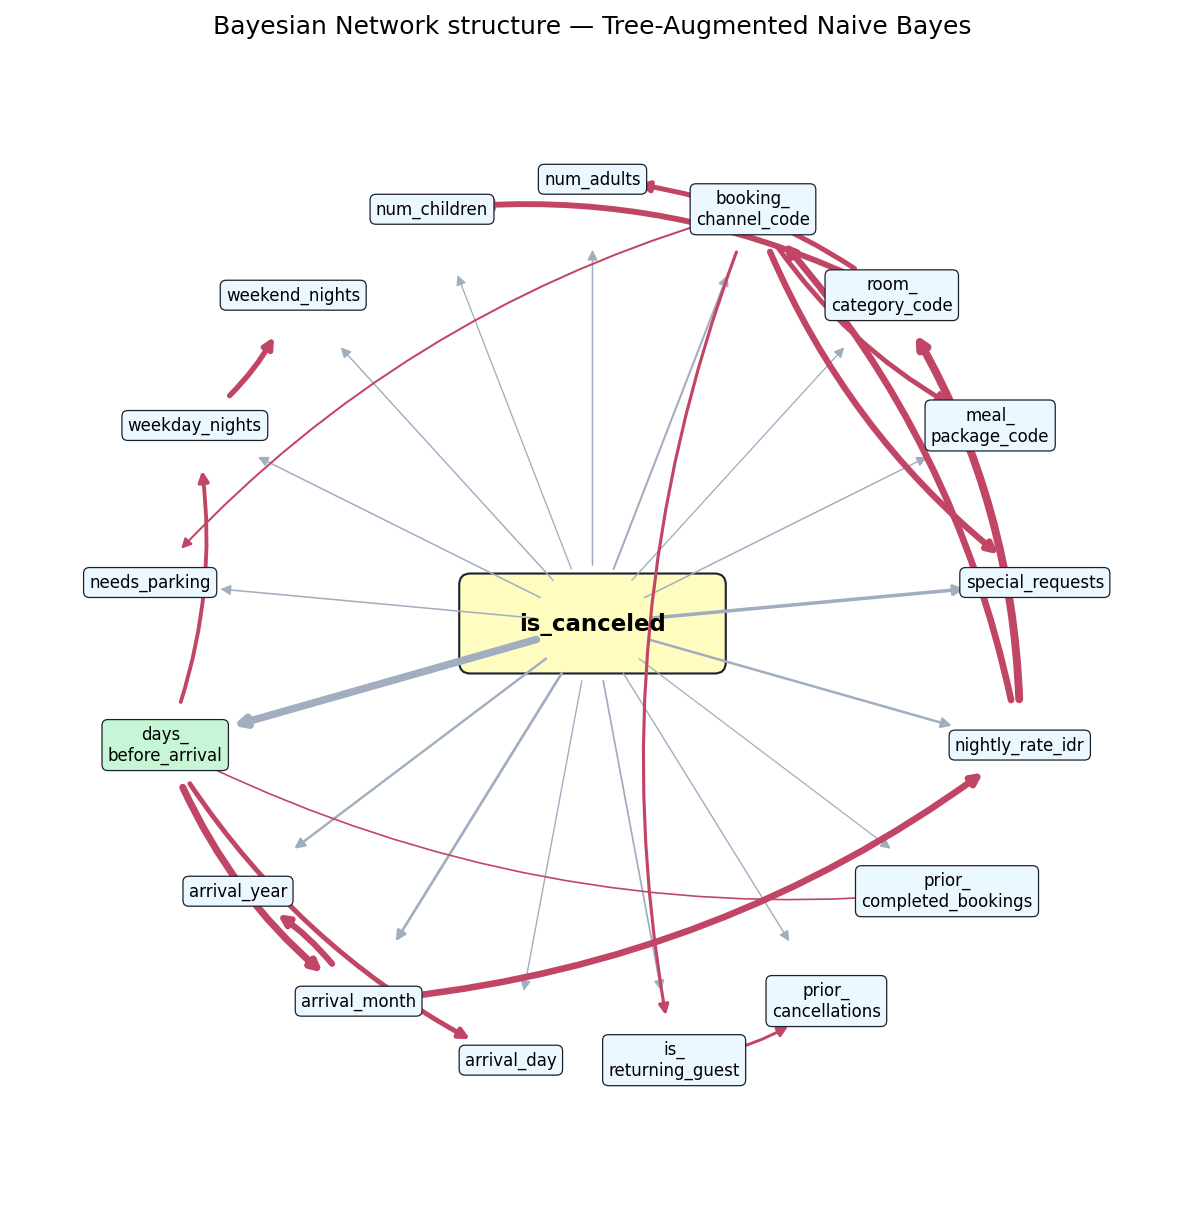

,feature,parent feature,CMI
14,room_category_code,nightly_rate_idr,0.1620
6,arrival_month,days_before_arrival,0.1408
15,booking_channel_code,nightly_rate_idr,0.1294
11,nightly_rate_idr,arrival_month,0.1280
12,special_requests,booking_channel_code,0.1195
5,arrival_year,arrival_month,0.1168
1,num_children,room_category_code,0.1092
2,weekend_nights,weekday_nights,0.0973


In [33]:
tan_fitted = results['TAN'].model
nb_feature_names = results['TAN'].pipeline.feature_names_
viz.plot_bayes_network(nb_feature_names, class_weights=tan_fitted.mi_class_, path=CFG.FIG_DIR / 'bayes_network_naive.png')
plt.close('all')
viz.plot_bayes_network(nb_feature_names, parents=tan_fitted.parent_, edge_weights=tan_fitted.cmi_,
                       class_weights=tan_fitted.mi_class_, path=CFG.FIG_DIR / 'bayes_network_tan.png')
plt.close('all')
display(Image(filename=str(CFG.FIG_DIR / 'bayes_network_naive.png'), width=480))
display(Image(filename=str(CFG.FIG_DIR / 'bayes_network_tan.png'), width=480))
edges = pd.DataFrame([{'feature': nb_feature_names[i], 'parent feature': nb_feature_names[p], 'CMI': tan_fitted.cmi_[i, p]}
                      for i, p in enumerate(tan_fitted.parent_) if p >= 0]).sort_values('CMI', ascending=False)
edges.to_csv(CFG.EXP_DIR / 'tan_edges.csv', index=False); display(edges.head(8))

### Bonus: cost-sensitive classification (FP = 2 × FN)

*False positive* (memprediksi batal padahal tamu datang) berbiaya 2 karena dapat menyebabkan *overbooking*, sedangkan
*false negative* berbiaya 1. Dengan P = P(batal | x), memprediksi "batal" berharapan biaya (1 − P)·c_FP dan
memprediksi "tidak batal" berharapan biaya P·c_FN, sehingga "batal" hanya diprediksi jika

$$P \ge \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{2}{3}$$

(Elkan 2001). Karena probabilitas KNN dan pohon tidak terkalibrasi sempurna, threshold yang meminimalkan biaya
*out-of-fold* juga dicari, lalu dibandingkan dengan pelatihan berbobot kelas (kelas 0 berbobot 2).

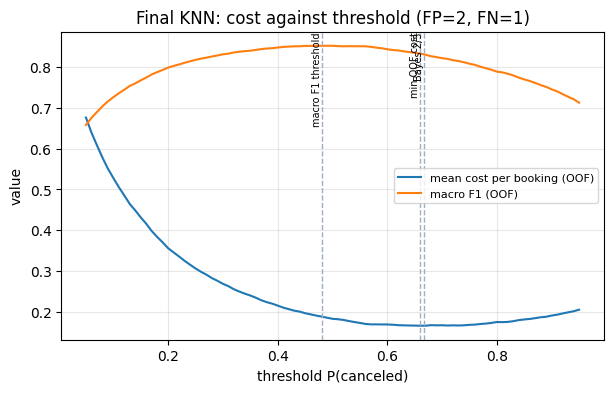

,threshold,FP,FN,total cost,cost/booking,precision canceled,recall canceled,macro_f1
scenario,,,,,,,,
KNN | macro F1 threshold,0.4800,300,367,967.0000,0.1766,0.8263,0.7954,0.8604
KNN | Bayes threshold 2/3,0.6667,138,580,856.0000,0.1563,0.8979,0.6767,0.8399
KNN | min OOF cost threshold,0.6600,139,574,852.0000,0.1556,0.8977,0.6800,0.8412
CART | macro F1 threshold,0.5200,296,458,"1,050.0000",0.1918,0.8186,0.7447,0.8399
"CART | class_weight 2:1, threshold 0.5",0.5000,110,751,971.0000,0.1774,0.9046,0.5814,0.8001
"LogReg | class_weight 2:1, threshold 0.5",0.5000,154,909,"1,217.0000",0.2223,0.8518,0.4933,0.7469


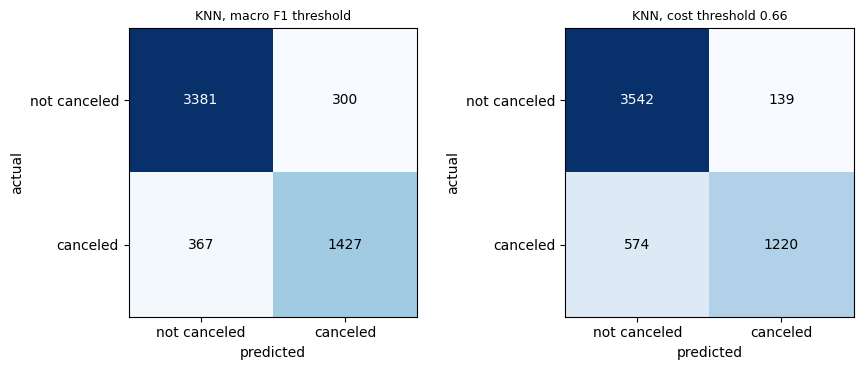

In [34]:
cost_cv = cv(knn_pipeline, knn_model)
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
cost_curve = np.array([metrics.misclassification_cost(y_dev, (cost_cv.oof_scores >= t).astype(int)) for t in grid]) / len(y_dev)
f1_curve = metrics.macro_f1_curve(y_dev, cost_cv.oof_scores, grid)
t_cost = float(grid[np.argmin(cost_curve)])
viz.plot_threshold_curve(grid, {'mean cost per booking (OOF)': cost_curve, 'macro F1 (OOF)': f1_curve},
                         path=CFG.FIG_DIR / 'cost_sensitive_threshold.png', ylabel='value',
                         mark=[(KNN_THRESHOLD, 'macro F1 threshold'), (2 / 3, 'Bayes 2/3'), (t_cost, 'min OOF cost')],
                         title='Final KNN: cost against threshold (FP=2, FN=1)')
plt.show()

knn_scores_hold = results['KNN'].scores
cart_cost = fit_and_score('CART class_weight {0:2, 1:1}', cart_pipeline(), cart_model(class_weight=[2.0, 1.0]), dev_df, y_dev, hold_df, 0.5)
lr_cost = fit_and_score('LogReg class_weight {0:2, 1:1}', lr_pipeline(), lr_model(class_weight=[2.0, 1.0]), dev_df, y_dev, hold_df, 0.5)
rows = []
for name, scores, thr in [('KNN | macro F1 threshold', knn_scores_hold, KNN_THRESHOLD),
                          ('KNN | Bayes threshold 2/3', knn_scores_hold, 2 / 3),
                          ('KNN | min OOF cost threshold', knn_scores_hold, t_cost),
                          ('CART | macro F1 threshold', results['CART'].scores, CART_THRESHOLD),
                          ('CART | class_weight 2:1, threshold 0.5', cart_cost.scores, 0.5),
                          ('LogReg | class_weight 2:1, threshold 0.5', lr_cost.scores, 0.5)]:
    pred = (scores >= thr).astype(int)
    cm = metrics.confusion_matrix(y_hold, pred, labels=[0, 1])
    rows.append({'scenario': name, 'threshold': thr, 'FP': cm[0, 1], 'FN': cm[1, 0],
                 'total cost': metrics.misclassification_cost(y_hold, pred), 'cost/booking': metrics.misclassification_cost(y_hold, pred) / len(y_hold),
                 'precision canceled': metrics.precision_recall_f1(y_hold, pred, [0, 1])[0][1],
                 'recall canceled': metrics.precision_recall_f1(y_hold, pred, [0, 1])[1][1], 'macro_f1': metrics.macro_f1(y_hold, pred)})
cost_table = pd.DataFrame(rows).set_index('scenario')
display(cost_table)
cost_table.to_csv(CFG.EXP_DIR / 'cost_sensitive_holdout.csv')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
viz.plot_confusion(metrics.confusion_matrix(y_hold, (knn_scores_hold >= KNN_THRESHOLD).astype(int), [0, 1]), axes[0], 'KNN, macro F1 threshold')
viz.plot_confusion(metrics.confusion_matrix(y_hold, (knn_scores_hold >= t_cost).astype(int), [0, 1]), axes[1], f'KNN, cost threshold {t_cost:.2f}')
fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'cost_sensitive_confusion.png', dpi=130); plt.show()

**Insights (cost-sensitive).** Ketika FP dua kali lebih mahal, threshold terbaik naik dari sekitar 0,5 (macro F1) ke
sekitar 2/3: model hanya menandai "batal" jika cukup yakin. FP turun tajam, FN naik, precision kelas batal naik, recall
turun, dan **biaya total turun** walaupun macro F1 sedikit turun, karena metrik yang dioptimalkan memang berbeda.
Threshold dari kurva biaya OOF (0,66) hampir sama dengan nilai teoretis 2/3, dan di hold-out keduanya memberi biaya
yang hampir sama, tanda probabilitas KNN cukup terkalibrasi. Pemberian
bobot kelas saat pelatihan (kelas 0 berbobot 2) juga menurunkan biaya CART tanpa mengubah threshold, tetapi untuk KNN
penggeseran threshold memberi biaya terendah. Dalam praktiknya, hotel sebaiknya memakai threshold biaya ini untuk
keputusan *overbooking*, sedangkan submisi Kaggle tetap memakai threshold macro F1.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

,macro_f1 from scratch,macro_f1 sklearn,accuracy from scratch,accuracy sklearn,prediction agreement,fit from scratch (s),fit sklearn (s)
model,,,,,,,
Weighted KNN,0.8604,0.8604,0.8782,0.8782,1.0000,0.0005,0.0030
KNN baseline k=5,0.8059,0.8059,0.8323,0.8323,1.0000,0.0022,0.0027
DTL CART (gini),0.8405,0.8373,0.8625,0.8601,0.9841,2.6354,0.3519
DTL ID3 (entropy),0.8355,0.8317,0.8570,0.8532,0.9662,2.3383,0.2875
DTL C4.5 (entropy + ccp_alpha),0.8382,0.8341,0.8617,0.8577,0.9777,2.3239,0.2774
DTL CART native categories vs sklearn,0.8399,0.8373,0.8623,0.8601,0.9810,2.4134,0.2036
LogReg L2,0.7858,0.7858,0.8128,0.8128,1.0000,0.6007,13.0661
LogReg L1,0.7839,0.7839,0.8117,0.8117,1.0000,0.9975,25.1275
LogReg Elastic Net,0.7829,0.7829,0.8104,0.8104,1.0000,1.0360,35.3881


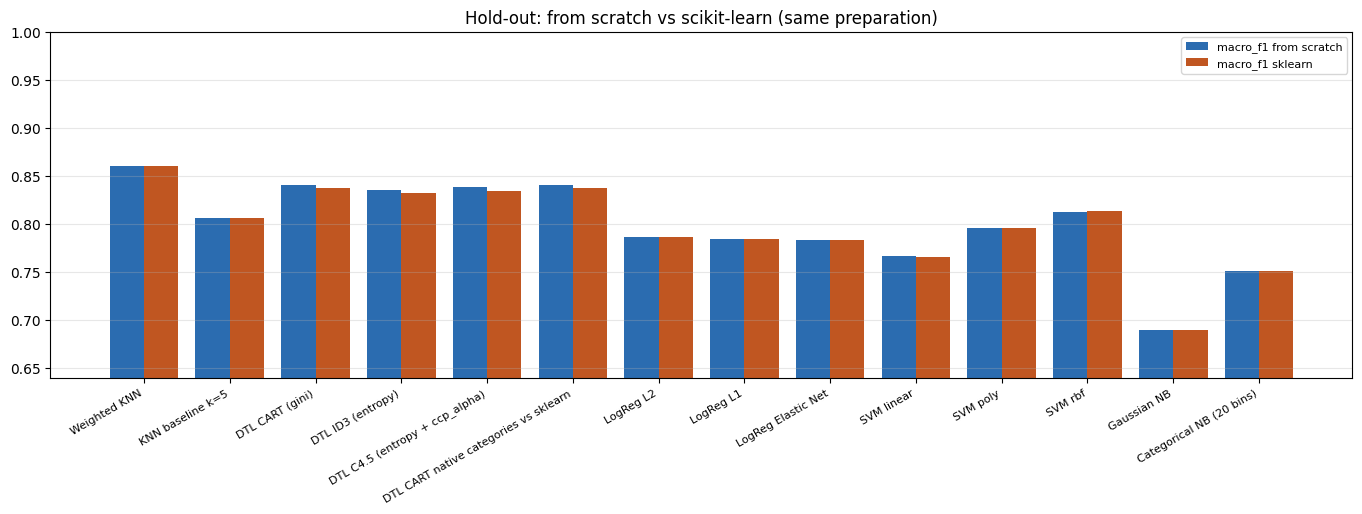

In [35]:
def compare(name, ours_model, sk_model, X_train, y_train, X_eval, threshold=0.5, ours_fit_kwargs=None):
    t0 = time.perf_counter(); ours_model.fit(X_train, y_train, **(ours_fit_kwargs or {})); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); sk_model.fit(X_train, y_train); t_sk = time.perf_counter() - t0
    if isinstance(ours_model, SVC):
        p_ours = ours_model.predict(X_eval); p_sk = sk_model.predict(X_eval)
    else:
        p_ours = (ours_model.predict_proba(X_eval)[:, 1] >= threshold).astype(int)
        p_sk = (sk_model.predict_proba(X_eval)[:, 1] >= threshold).astype(int)
    return {'model': name, 'macro_f1 from scratch': metrics.macro_f1(y_hold, p_ours), 'macro_f1 sklearn': metrics.macro_f1(y_hold, p_sk),
            'accuracy from scratch': metrics.accuracy(y_hold, p_ours), 'accuracy sklearn': metrics.accuracy(y_hold, p_sk),
            'prediction agreement': float(np.mean(p_ours == p_sk)), 'fit from scratch (s)': t_ours, 'fit sklearn (s)': t_sk}

rows = []
Xk_tr, Xk_ev = results['KNN'].pipeline.transform(dev_df), results['KNN'].pipeline.transform(hold_df)
power = KNN_PARAMS.get('distance_power', 1.0)
sk_weights = (lambda d: 1.0 / np.maximum(d, 1e-12) ** power) if power != 1.0 else 'distance'
rows.append(compare('Weighted KNN', knn_model(), SkKNN(KNN_PARAMS['n_neighbors'], metric=KNN_PARAMS['metric'], weights=sk_weights, algorithm='brute'),
                    Xk_tr, y_dev, Xk_ev, KNN_THRESHOLD))
Xb_tr, Xb_ev = results['KNN baseline'].pipeline.transform(dev_df), results['KNN baseline'].pipeline.transform(hold_df)
rows.append(compare('KNN baseline k=5', KNNClassifier(**config.KNN_BASELINE_PARAMS), SkKNN(5, algorithm='brute'), Xb_tr, y_dev, Xb_ev))
for label, ours, sk in [('DTL CART (gini)', CARTClassifier('gini', max_depth=12, ccp_alpha=2e-4), SkTree(criterion='gini', max_depth=12, ccp_alpha=2e-4, random_state=CFG.SEED)),
                        ('DTL ID3 (entropy)', CARTClassifier('entropy', max_depth=12, min_samples_leaf=5), SkTree(criterion='entropy', max_depth=12, min_samples_leaf=5, random_state=CFG.SEED)),
                        ('DTL C4.5 (entropy + ccp_alpha)', CARTClassifier('entropy', max_depth=12, ccp_alpha=4e-4), SkTree(criterion='entropy', max_depth=12, ccp_alpha=4e-4, random_state=CFG.SEED))]:
    rows.append(compare(label, ours, sk, X_dev_tree, y_dev, X_hold_tree, 0.5))
rows.append(compare('DTL CART native categories vs sklearn', CARTClassifier('gini', max_depth=12, ccp_alpha=2e-4),
                    SkTree(criterion='gini', max_depth=12, ccp_alpha=2e-4, random_state=CFG.SEED), X_dev_tree, y_dev, X_hold_tree, 0.5,
                    ours_fit_kwargs={'categorical_features': cat_idx}))
for label, params, skparams in [('LogReg L2', dict(penalty='l2', C=3.0), dict(penalty='l2', C=3.0, solver='lbfgs')),
                                ('LogReg L1', dict(penalty='l1', C=0.05), dict(penalty='l1', C=0.05, solver='saga')),
                                ('LogReg Elastic Net', dict(penalty='elasticnet', C=0.05, l1_ratio=0.5), dict(penalty='elasticnet', C=0.05, l1_ratio=0.5, solver='saga'))]:
    rows.append(compare(label, LogisticRegression(solver='newton', max_iter=200, **params), SkLogReg(max_iter=5000, tol=1e-6, **skparams),
                        X_dev_lr, y_dev, X_hold_lr, LR_THRESHOLD))
Xs_tr, ys_tr = take_svm(results['SVM rbf'].pipeline.transform(dev_df), y_dev)
Xs_ev = results['SVM rbf'].pipeline.transform(hold_df)
for kernel in ['linear', 'poly', 'rbf']:
    params = config.SVM_PARAMS[kernel]
    rows.append(compare(f'SVM {kernel}', SVC(**params), SkSVC(**params), Xs_tr, ys_tr, Xs_ev))
nb_imp = make_pipeline('bayes', impute='median', derived=[], indicators=())
Xn_tr, Xn_ev = nb_imp.fit_transform(dev_df, y_dev), nb_imp.transform(hold_df)
rows.append(compare('Gaussian NB', NaiveBayes('gaussian'), SkGaussianNB(), Xn_tr, y_dev, Xn_ev))
disc = NaiveBayes('discretize', 20).fit(Xn_tr, y_dev).discretizer_
Xd_tr, Xd_ev = disc.transform(Xn_tr), disc.transform(Xn_ev)
Xd_tr, Xd_ev = np.nan_to_num(Xd_tr), np.nan_to_num(Xd_ev)
rows.append(compare('Categorical NB (20 bins)', NaiveBayes('gaussian', categorical_features=list(range(Xd_tr.shape[1]))),
                    SkCategoricalNB(alpha=1.0, min_categories=np.array(disc.cardinalities())), Xd_tr, y_dev, Xd_ev))
comparison = pd.DataFrame(rows).set_index('model')
display(comparison)
comparison.to_csv(CFG.EXP_DIR / 'sklearn_comparison.csv')
viz.plot_metric_comparison(comparison, ['macro_f1 from scratch', 'macro_f1 sklearn'], path=CFG.FIG_DIR / 'sklearn_comparison.png',
                           title='Hold-out: from scratch vs scikit-learn (same preparation)')
plt.show()

---

# Saving and Loading Models <a name="9"></a>

---


This section stores the trained models and restores them for prediction.

In [36]:
saved = {}
for key, threshold in [('KNN', KNN_THRESHOLD), ('CART', CART_THRESHOLD), ('LogReg', LR_THRESHOLD),
                       ('SVM rbf', config.SVM_THRESHOLDS['rbf']), ('NaiveBayes', 0.5), ('TAN', 0.5)]:
    res = results[key]
    path = res.model.save(CFG.MODEL_DIR / f"{key.replace(' ', '_').lower()}_model.pkl")
    with open(CFG.MODEL_DIR / f"{key.replace(' ', '_').lower()}_pipeline.pkl", 'wb') as handle:
        pickle.dump({'pipeline': res.pipeline, 'threshold': threshold}, handle)
    saved[key] = path

check = []
for key, path in saved.items():
    model_cls = type(results[key].model)
    loaded = model_cls.load(path)
    with open(str(path).replace('_model.pkl', '_pipeline.pkl'), 'rb') as handle:
        bundle = pickle.load(handle)
    X_check = bundle['pipeline'].transform(hold_df)
    same = np.array_equal(loaded.predict_proba(X_check), results[key].model.predict_proba(X_check))
    check.append({'model': key, 'file': path.name, 'size (KB)': path.stat().st_size / 1024, 'same predictions after load': same})
display(pd.DataFrame(check).set_index('model'))

,file,size (KB),same predictions after load
model,,,
KNN,knn_model.pkl,"3,443.7705",True
CART,cart_model.pkl,50.2764,True
LogReg,logreg_model.pkl,2.0918,True
SVM rbf,svm_rbf_model.pkl,452.0254,True
NaiveBayes,naivebayes_model.pkl,4.6904,True
TAN,tan_model.pkl,31.5742,True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [37]:
y_full = train_df[TARGET].to_numpy()
final_pipeline = knn_pipeline()
X_full = final_pipeline.fit_transform(train_df, y_full)
final_model = knn_model().fit(X_full, y_full)
test_scores = final_model.predict_proba(final_pipeline.transform(test_df))[:, 1]
test_pred = (test_scores >= KNN_THRESHOLD).astype(int)

submission = pd.DataFrame({'id': test_df[ID_COLUMN], 'is_canceled': test_pred})
assert submission.shape == sample_submission.shape and (submission['id'] == sample_submission['id']).all()
assert set(submission['is_canceled'].unique()) <= {0, 1}
submission_path = CFG.SUB_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
final_model.save(CFG.MODEL_DIR / 'final_knn_full_train.pkl')
with open(CFG.MODEL_DIR / 'final_knn_full_train_pipeline.pkl', 'wb') as handle:
    pickle.dump({'pipeline': final_pipeline, 'threshold': KNN_THRESHOLD}, handle)

print('File:', submission_path.relative_to(CFG.ROOT))
print('Share of predicted cancellations in test: %.4f (train: %.4f)' % (test_pred.mean(), y_full.mean()))
print('SHA-256:', hashlib.sha256(submission_path.read_bytes()).hexdigest())
display(submission.head())

File: output/submissions/submission.csv
Share of predicted cancellations in test: 0.3052 (train: 0.3277)
SHA-256: dd1c28ba279e3fc8cf94f1a47d40af4e7f83345e618c1a73324bc70dd547f257


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


Cadangan: CART final yang dilatih dengan cara yang sama (untuk submisi kedua dari jenis model yang berbeda).

In [38]:
backup_pipeline = cart_pipeline()
backup_model = cart_model().fit(*backup_pipeline.fit_resample(train_df, y_full), **backup_pipeline.fit_kwargs)
backup_pred = (backup_model.predict_proba(backup_pipeline.transform(test_df))[:, 1] >= CART_THRESHOLD).astype(int)
backup_path = CFG.SUB_DIR / 'submission_cart.csv'
pd.DataFrame({'id': test_df[ID_COLUMN], 'is_canceled': backup_pred}).to_csv(backup_path, index=False)
print('Backup file:', backup_path.relative_to(CFG.ROOT), '| SHA-256:', hashlib.sha256(backup_path.read_bytes()).hexdigest())
print('KNN vs CART agreement on test: %.4f' % np.mean(backup_pred == test_pred))

Backup file: output/submissions/submission_cart.csv | SHA-256: 1dac204d754a47b35bd2d120bc1c8b5fb3c0d23e9167b354fbe1ff50280fef8f
KNN vs CART agreement on test: 0.9001


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

,column,value,n,cancel_rate,error_rate,macro_f1
21,lead_time,"(81.0, 151.0]",1034,0.3520,0.1809,0.8012
27,room_category,Type D,85,0.3294,0.1765,0.8053
30,room_category,Type G,889,0.3420,0.1552,0.8299
4,booking_channel,Online Travel Agent,3475,0.3658,0.1542,0.8326
20,lead_time,"(38.0, 81.0]",1072,0.2528,0.1521,0.8063
7,special_requests,(missing),471,0.3885,0.1507,0.8452
23,room_category,(missing),191,0.2932,0.1414,0.8303
9,special_requests,1.0,1655,0.2429,0.1390,0.7848
6,arrival_year,2024,4476,0.3653,0.1318,0.8572
22,lead_time,(missing),214,0.3318,0.1308,0.8491


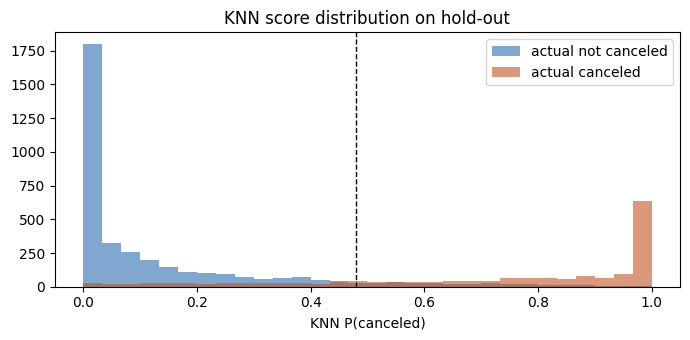

False positives with the highest score:


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,room_category,booking_channel,score
3233,2.0000,0.0000,2,1,0.0000,99.0000,2023,7,18,0,0,0,NaN,0.0000,Half Board,Type B,Offline Agent,1.0000
1667,2.0000,0.0000,2,1,0.0000,133.0000,2023,8,15,0,0,0,"1,520,000.0000",0.0000,Half Board,Type B,Offline Agent,0.9992
5397,2.0000,0.0000,0,1,0.0000,5.0000,2024,2,13,0,0,0,"1,456,000.0000",0.0000,Room Only,Type B,Online Travel Agent,0.9949
2857,2.0000,0.0000,1,2,0.0000,66.0000,2024,6,16,0,0,0,"2,142,000.0000",0.0000,Breakfast,Type B,Online Travel Agent,0.9934
2715,2.0000,0.0000,2,5,0.0000,137.0000,2024,7,30,0,0,0,NaN,0.0000,Breakfast,Type G,Online Travel Agent,0.9931


False negatives with the lowest score:


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,room_category,booking_channel,score
758,1.0000,0.0000,0,2,0.0000,NaN,2024,6,14,0,0,0,"2,191,000.0000",0.0000,NaN,NaN,Offline Agent,0.0000
4534,2.0000,0.0000,0,2,0.0000,103.0000,2023,10,16,0,0,0,NaN,0.0000,Half Board,Type B,Offline Agent,0.0000
1275,2.0000,0.0000,0,5,0.0000,29.0000,2024,10,3,0,0,0,"2,592,000.0000",2.0000,Breakfast,Type G,Online Travel Agent,0.0000
1259,2.0000,0.0000,1,0,0.0000,0.0000,2024,7,31,0,0,0,"1,807,000.0000",1.0000,Room Only,Type B,Online Travel Agent,0.0000
2277,1.0000,0.0000,0,2,0.0000,197.0000,2024,6,23,0,0,0,NaN,0.0000,Breakfast,Type B,Offline Agent,0.0000


In [39]:
knn_hold_pred = results['KNN'].predictions
analysis_df = hold_df.copy()
analysis_df['n_missing'] = hold_df[RAW_FEATURES].isna().sum(axis=1).clip(upper=2).astype(str)
analysis_df['lead_time'] = hold_df['days_before_arrival']
segments = segment_errors(analysis_df, y_hold, knn_hold_pred,
                          ['booking_channel', 'arrival_year', 'special_requests', 'n_missing', 'lead_time', 'room_category'])
segments.to_csv(CFG.EXP_DIR / 'error_segments.csv', index=False)
display(segments[segments['n'] >= 30].sort_values('error_rate', ascending=False).head(15))

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, color in [(0, viz.COLORS['neg']), (1, viz.COLORS['pos'])]:
    ax.hist(results['KNN'].scores[y_hold == label], bins=30, alpha=0.6, color=color, label=['actual not canceled', 'actual canceled'][label])
ax.axvline(KNN_THRESHOLD, color='k', ls='--', lw=1); ax.set_xlabel('KNN P(canceled)'); ax.legend()
ax.set_title('KNN score distribution on hold-out'); fig.tight_layout(); fig.savefig(CFG.FIG_DIR / 'error_score_distribution.png', dpi=130); plt.show()

errors = hold_df.assign(score=results['KNN'].scores, pred=knn_hold_pred)
print('False positives with the highest score:')
display(errors[(errors.pred == 1) & (errors[TARGET] == 0)].sort_values('score', ascending=False).head(5)[RAW_FEATURES + ['score']])
print('False negatives with the lowest score:')
display(errors[(errors.pred == 0) & (errors[TARGET] == 1)].sort_values('score').head(5)[RAW_FEATURES + ['score']])